# **Explainable Cross-Departmental Expert Recommendation via Knowledge Graph Reasoning on Heterogeneous Academic Network**

Riset Mandiri Semester 5 | Abdullah Al-Firdaus | Universitas Negeri Surabaya

## **1. Persiapan Library dan Seed**

### 1.1 Pemeriksaan Library

In [1]:
import importlib.util

package = {
    'pandas': 'pandas',
    'numpy': 'numpy',
    'yake': 'yake',
    'sentence_transformers': 'sentence-transformers',
    'rank_bm25': 'rank-bm25',
    'networkx': 'networkx',
    'matplotlib': 'matplotlib',
    'torch': 'torch',
    'torch_geometric': 'torch-geometric',
}

kurang = [pip for modul, pip in package.items() if importlib.util.find_spec(modul) is None]

### 1.2 Import Library

In [2]:
import os
import re
import random
import itertools
from collections import defaultdict

import numpy as np
import scipy.sparse as sp
import pandas as pd
from IPython.display import display

import yake
from sentence_transformers import SentenceTransformer, util
from rank_bm25 import BM25Okapi

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch_geometric.data import HeteroData
from torch_geometric.nn import HANConv, HGTConv, HeteroConv, SAGEConv, Linear
from torch_geometric.utils import softmax

import networkx as nx
import matplotlib.pyplot as plt

C:\Users\Abdullah Al-Firdaus\AppData\Roaming\Python\Python310\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Abdullah Al-Firdaus\AppData\Roaming\Python\Python310\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


### 1.3 Pengaturan Seed

Seluruh hasil seed di bagian 7–10 memakai `SEED = 42`, sedangkan hasil akhir dari rata-rata beberapa seed di bab 11 (Sandve dkk., 2013, [10.1371/journal.pcbi.1003285](https://doi.org/10.1371/journal.pcbi.1003285)).

Ternyata seed saja belum membuat hasilnya sama ketika python dijalankan. Ada dua penyebab yang ditemukan:

1. Python mengacak nilai hash string di setiap proses ([dokumentasi Python](https://docs.python.org/3/reference/datamodel.html#object.__hash__)), sehingga urutan iterasi `set` berisi string berubah setiap kernel dinyalakan ulang. Ini memengaruhi urutan edge antarprodi (6.3) dan urutan dosen yang skornya seri (7.3), jadi keduanya kini diurutkan dulu dengan `sorted`.
2. Melatih HAN dua kali dengan seed yang sama dalam satu sesi menghasilkan bobot yang berbeda hingga 0,6. Setelah `torch.use_deterministic_algorithms(True)` diaktifkan ([dokumentasi PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.use_deterministic_algorithms.html)), hasilnya identik dengan waktu latih yang hampir sama.

In [3]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.use_deterministic_algorithms(True)

## **2. Load Data**

`dosen_infokom_final.csv` berisi 129 dosen beserta prodi, Scholar ID, Scopus ID, dan SINTA ID, yang menjadi daftar acuan siapa saja dosen kita dan dari prodi mana. `merged_clean_fixed.csv` berisi 6.160 publikasi (judul, tahun, jurnal, keyword, dan penulis) yang menjadi bahan utama untuk membangun graph.

Dua file hasil scraping mentah, `dosen_papers_scholar.csv` dan `dosen_papers_scopus.csv`, baru dipakai di 3.3 untuk memeriksa nama penulis asli.

### 2.1 Membaca File

In [4]:
FOLDER_DATASET = 'data'

path_papers = os.path.join(FOLDER_DATASET, 'merged_clean_fixed.csv')
path_dosen = os.path.join(FOLDER_DATASET, 'dosen_infokom_final.csv')

df_papers = pd.read_csv(path_papers, sep=';', encoding='cp1252', on_bad_lines='warn')
df_dosen = pd.read_csv(path_dosen, encoding='utf-8')

df_papers['paper_id'] = range(len(df_papers))

print(f"  df_papers : {df_papers.shape[0]:,} baris x {df_papers.shape[1]} kolom")
print(f"  df_dosen  : {df_dosen.shape[0]:,} baris x {df_dosen.shape[1]} kolom")

  df_papers : 6,160 baris x 11 kolom
  df_dosen  : 129 baris x 9 kolom


### 2.2 Pemeriksaan Kolom

In [5]:
def periksa_kolom(df, nama_tabel):
    kosong = df.isna().sum()

    ringkasan = pd.DataFrame({
        'Tipe Data': df.dtypes.astype(str),
        'Kosong': kosong,
        '% Kosong': (kosong / len(df) * 100).round(1),
        'Nilai Unik': df.nunique(),
    })
    ringkasan.index.name = 'Kolom'

    print(f"{nama_tabel} - {len(df):,} baris")
    display(ringkasan)

periksa_kolom(df_papers, "TABEL PUBLIKASI (df_papers)")
periksa_kolom(df_dosen, "TABEL DOSEN (df_dosen)")

TABEL PUBLIKASI (df_papers) - 6,160 baris


,Tipe Data,Kosong,% Kosong,Nilai Unik
Kolom,,,,
Title,object,0,0.0,6160
Year,int64,0,0.0,32
Journal,object,0,0.0,2020
Keywords,object,183,3.0,5739
Document Type,object,0,0.0,6
DOI,object,5087,82.6,1072
Unesa Authors,object,0,0.0,1189
IEEE-Keywords,object,0,0.0,5682
_source,object,0,0.0,2


TABEL DOSEN (df_dosen) - 129 baris


,Tipe Data,Kosong,% Kosong,Nilai Unik
Kolom,,,,
nama_dosen,object,0,0.0,129
nama_norm,object,0,0.0,129
nip,float64,0,0.0,39
nidn,float64,14,10.9,115
prodi,object,0,0.0,24
scholar_id,object,0,0.0,126
scopus_id,object,0,0.0,121
sinta_id,float64,22,17.1,107
source,object,0,0.0,3


### 2.3 Contoh Isi Data

In [6]:
def tampilkan_satu_baris(df, nomor_baris, nama_tabel):
    baris = df.iloc[nomor_baris]
    print(f"\nCONTOH BARIS KE-{nomor_baris} DARI {nama_tabel}")
    for kolom in df.columns:
        isi = str(baris[kolom])
        if len(isi) > 95:
            isi = isi[:95] + " ..."
        print(f"  {kolom:<18}: {isi}")

tampilkan_satu_baris(df_papers, 0, "TABEL PUBLIKASI")
tampilkan_satu_baris(df_dosen, 0, "TABEL DOSEN")


CONTOH BARIS KE-0 DARI TABEL PUBLIKASI
  Title             : Perancangan Dan Implementasi Sistem Penyimpanan Digital Berbasis Web Di Cv. Skm Indonesia
  Year              : 2026
  Journal           : Journal of Informatics and Computer Science (JINACS)
  Keywords          : digital certificates;educational technology;digital learning;software design;software requireme ...
  Document Type     : journal article
  DOI               : nan
  Unesa Authors     : WdhKN0sAAAAJ
  IEEE-Keywords     : it applications;systems and software;computer system implementation;internet applications;infor ...
  _source           : google_scholar
  Unesa Names       : Aditya Prapanca
  paper_id          : 0

CONTOH BARIS KE-0 DARI TABEL DOSEN
  nama_dosen        : Aditya Prapanca, S.T., M.Kom.
  nama_norm         : Aditya Prapanca
  nip               : 1.97e+17
  nidn              : 1117406.0
  prodi             : S1 Teknik Informatika
  scholar_id        : WdhKN0sAAAAJ
  scopus_id         : 57215981815
  

### 2.4 Ringkasan Cakupan Data

In [7]:
df_papers['Year'] = pd.to_numeric(df_papers['Year'], errors='coerce')
tahun_tidak_valid = int(df_papers['Year'].isna().sum())

print("Rentang Waktu Publikasi")
print(f" Tahun paling awal  : {int(df_papers['Year'].min())}")
print(f" Tahun paling akhir : {int(df_papers['Year'].max())}")
print(f" Tahun tidak valid  : {tahun_tidak_valid}")

print("\nAsal Data Paper")
for sumber, jumlah in df_papers['_source'].value_counts().items():
    print(f"  {sumber:<16}: {jumlah:>6,} paper ({jumlah / len(df_papers) * 100:.1f}%)")

print("\nSebaran Dosen per Prodi")
print(f" Jumlah prodi: {df_dosen['prodi'].nunique()}")
print(" 5 prodi dengan dosen terbanyak:")
for prodi, jumlah in df_dosen['prodi'].value_counts().head().items():
    print(f" {prodi:<38}: {jumlah:>3} dosen")

print("\nJenis Dokumen Paper")
for jenis, jumlah in df_papers['Document Type'].value_counts().items():
    print(f" {jenis:<26}: {jumlah:>6,}")

Rentang Waktu Publikasi
 Tahun paling awal  : 1990
 Tahun paling akhir : 2027
 Tahun tidak valid  : 0

Asal Data Paper
  google_scholar  :  5,313 paper (86.2%)
  scopus          :    847 paper (13.8%)

Sebaran Dosen per Prodi
 Jumlah prodi: 24
 5 prodi dengan dosen terbanyak:
 S1 Bisnis Digital                     :  16 dosen
 S1 Pendidikan Teknologi Informasi     :  15 dosen
 S1 Sains Data                         :  13 dosen
 D4 Manajemen Informatika              :  13 dosen
 S1 Teknik Elektro                     :  12 dosen

Jenis Dokumen Paper
 journal article           :  5,623
 conference paper          :    516
 book chapter              :     10
 review                    :      8
 dissertation              :      2
 data paper                :      1


## **3. Pembersihan Scholar ID**

### 3.1 Pemeriksaan Format ID

In [8]:
df_dosen['scholar_id'] = df_dosen['scholar_id'].astype(str).str.strip()

panjang = df_dosen['scholar_id'].str.len()

print(f"Panjang karakter yang ditemukan : {sorted(panjang.unique().tolist())}")
print(f"ID dengan panjang tidak wajar   : {(panjang != 12).sum()}")

display(df_dosen[panjang != 12][['nama_dosen', 'prodi', 'scholar_id']])

Panjang karakter yang ditemukan : [12, 15]
ID dengan panjang tidak wajar   : 1


Kolom,nama_dosen,prodi,scholar_id
3,"Agus Prihanto, S.T., M.Kom.",S1 Teknik Informatika,-_VNTSIAAAAJ&hl


### 3.2 Perbaikan Format ID

In [9]:
df_dosen['scholar_id'] = df_dosen['scholar_id'].str.split('&').str[0]

panjang = df_dosen['scholar_id'].str.len()

print(f"Panjang karakter sekarang : {sorted(panjang.unique().tolist())}")
print(f"Semua 12 karakter         : {(panjang == 12).all()}")
print(f"Scholar ID unik           : {df_dosen['scholar_id'].nunique()} dari {len(df_dosen)} dosen")

Panjang karakter sekarang : [12]
Semua 12 karakter         : True
Scholar ID unik           : 126 dari 129 dosen


### 3.3 Deteksi Scholar ID Ganda

In [10]:
hitungan = df_dosen['scholar_id'].value_counts()
id_ganda = hitungan[hitungan > 1].index.tolist()

print(f"Scholar ID yang dipakai lebih dari satu dosen: {len(id_ganda)}")

display(df_dosen[df_dosen['scholar_id'].isin(id_ganda)]
        .sort_values('scholar_id')[['scholar_id', 'nama_dosen', 'prodi']])

Scholar ID yang dipakai lebih dari satu dosen: 3


Kolom,scholar_id,nama_dosen,prodi
7,Em3aIV0AAAAJ,"Paramitha Nerisafitra, S.ST., M.Kom.",S1 Teknik Informatika
32,Em3aIV0AAAAJ,"Ramadhan Cakra Wibawa, S.Pd., M.Kom.",S1 Pendidikan Teknologi Informasi
39,iFSMsegAAAAJ,"Mohammad Wildan Habibi, S.Pd., M.Pd.",S1 Pendidikan Teknologi Informasi
40,iFSMsegAAAAJ,"Elvira Wardah, S.Pd., M.Ed.",S1 Pendidikan Teknologi Informasi
9,nyyfjCgAAAAJ,"Ervin Yohannes, S.Kom., M.Kom., M.Sc., Ph.D.",S2 Informatika
11,nyyfjCgAAAAJ,"Rifqi Abdillah, M.Kom.",S1 Teknik Informatika


6 dosen kami cek lewat SINTA (*Science and Technology Index*). Hasilnya, pemilik ketiga ID adalah dosen yang tercantum lebih dulu di tabel: 

- Paramitha Nerisafitra, 
- Ervin Yohannes, dan 
- Mohammad Wildan Habibi. 

Tiga dosen lainnya punya Scholar ID sendiri yang belum tercatat di tabel dosen.

| Dosen | Prodi | Scholar ID menurut SINTA | Profil SINTA |
|---|---|---|---|
| Paramitha Nerisafitra | S1 Teknik Informatika | `Em3aIV0AAAAJ` | [6937234](https://sinta.kemdiktisaintek.go.id/authors/profile/6937234) |
| Ramadhan Cakra Wibawa | S1 Pendidikan Teknologi Informasi | `_B1ZJi4AAAAJ` | [6788230](https://sinta.kemdiktisaintek.go.id/authors/profile/6788230) |
| Ervin Yohannes | S2 Informatika | `nyyfjCgAAAAJ` | [6893377](https://sinta.kemdiktisaintek.go.id/authors/profile/6893377) |
| Rifqi Abdillah | S1 Teknik Informatika | `S2oIBtYAAAAJ` | [6902707](https://sinta.kemdiktisaintek.go.id/authors/profile/6902707) |
| Mohammad Wildan Habibi | S1 Pendidikan Teknologi Informasi | `iFSMsegAAAAJ` | [6921547](https://sinta.kemdiktisaintek.go.id/authors/profile/6921547) |
| Elvira Wardah | S1 Pendidikan Teknologi Informasi | `j3dVj60AAAAJ` | [7020774](https://sinta.kemdiktisaintek.go.id/authors/profile/7020774) |

**Profil SINTA diakses 1 Oktober 2026.*

Ferreira dkk. (2012), *ACM SIGMOD Record* ([10.1145/2350036.2350040](https://doi.org/10.1145/2350036.2350040)):

> *"Name ambiguity in the context of bibliographic citation records is a hard problem that affects the quality of services and content in digital libraries and similar systems."*

Sandve dkk. (2013), *PLoS Computational Biology*, Rule 2 ([10.1371/journal.pcbi.1003285](https://doi.org/10.1371/journal.pcbi.1003285)):

> *"Whenever possible, rely on the execution of programs instead of manual procedures to modify data. Such manual procedures are not only inefficient and error-prone, they are also difficult to reproduce."*

Karena itu, kepemilikan ketiga Scholar ID ditelusuri ulang lewat SINTA, lalu koreksinya ditulis di sel berikut, bukan dengan dataset CSV.

In [11]:
KOREKSI_SCHOLAR_ID = {
    'Ramadhan Cakra Wibawa': '_B1ZJi4AAAAJ',
    'Rifqi Abdillah': 'S2oIBtYAAAAJ',
    'Elvira Wardah': 'j3dVj60AAAAJ',
}

for nama, sid in KOREKSI_SCHOLAR_ID.items():
    df_dosen.loc[df_dosen['nama_dosen'].str.startswith(nama), 'scholar_id'] = sid

display(df_dosen[df_dosen['nama_dosen'].str.startswith(tuple(KOREKSI_SCHOLAR_ID))]
        [['scholar_id', 'nama_dosen', 'prodi']])

print(f"Jumlah dosen    : {len(df_dosen)}")
print(f"Scholar ID unik : {df_dosen['scholar_id'].nunique()}  (1 ID = 1 dosen = 1 prodi)")

Kolom,scholar_id,nama_dosen,prodi
11,S2oIBtYAAAAJ,"Rifqi Abdillah, M.Kom.",S1 Teknik Informatika
32,_B1ZJi4AAAAJ,"Ramadhan Cakra Wibawa, S.Pd., M.Kom.",S1 Pendidikan Teknologi Informasi
40,j3dVj60AAAAJ,"Elvira Wardah, S.Pd., M.Ed.",S1 Pendidikan Teknologi Informasi


Jumlah dosen    : 129
Scholar ID unik : 129  (1 ID = 1 dosen = 1 prodi)


Setiap paper yang memuat nama dari tiga ID itu dicocokkan lewat judul dengan daftar penulis aslinya di `dosen_papers_scholar.csv` dan `dosen_papers_scopus.csv`, lalu Scholar ID-nya diberikan kepada dosen yang namanya tercantum.

Ferreira dkk. (2012), *ACM SIGMOD Record* ([10.1145/2350036.2350040](https://doi.org/10.1145/2350036.2350040)):

> *"Generally speaking, the proposed methods usually attempt to group citation records of a same author by finding some similarity among them or try to directly assign them to their respective authors."*

In [12]:
def kunci_judul(judul):
    return re.sub(r'[^a-z0-9]', '', str(judul).lower())[:60]

mentah = pd.concat([
    pd.read_csv(os.path.join(FOLDER_DATASET, 'dosen_papers_scholar.csv'), on_bad_lines='skip'),
    pd.read_csv(os.path.join(FOLDER_DATASET, 'dosen_papers_scopus.csv'), on_bad_lines='skip'),
])
penulis_asli = (mentah.assign(kunci=mentah['Title'].map(kunci_judul))
                .groupby('kunci')['Authors']
                .apply(lambda x: ' | '.join(x.dropna().astype(str))))

POLA_PENULIS = {
    'Em3aIV0AAAAJ': {'Em3aIV0AAAAJ': r'Paramitha Nerisafitra|Nerisafitra',
                     '_B1ZJi4AAAAJ': r'Ramadhan Cakra Wibawa|R\.\s?C\.\s?Wibawa'},
    'nyyfjCgAAAAJ': {'nyyfjCgAAAAJ': r'Ervin Yohannes|Yohannes',
                     'S2oIBtYAAAAJ': r'Rifqi Abdillah|R\.\s?Abdillah'},
    'iFSMsegAAAAJ': {'iFSMsegAAAAJ': r'Mohammad Wildan Habibi|M\.\s?W\.\s?Habibi',
                     'j3dVj60AAAAJ': r'Elvira Wardah|E\.\s?Wardah'},
}

def perbaiki_penulis(baris):
    asli = penulis_asli.get(kunci_judul(baris['Title']), '')
    hasil = []
    for sid in str(baris['Unesa Authors']).split(';'):
        sid = sid.strip()
        if sid in POLA_PENULIS:
            cocok = [s for s, pola in POLA_PENULIS[sid].items()
                     if re.search(pola, asli, flags=re.IGNORECASE)]
            hasil += cocok or [sid]
        elif sid:
            hasil.append(sid)
    return ';'.join(dict.fromkeys(hasil))

terdampak = df_papers['Unesa Authors'].fillna('').str.contains('|'.join(POLA_PENULIS))
sebelum = df_papers.loc[terdampak, 'Unesa Authors'].copy()
df_papers.loc[terdampak, 'Unesa Authors'] = df_papers.loc[terdampak].apply(perbaiki_penulis, axis=1)
sesudah = df_papers.loc[terdampak, 'Unesa Authors']

ringkas_atribusi = []
for sid, calon in POLA_PENULIS.items():
    kena = sebelum.str.contains(sid)
    pasangan = [s for s in calon if s != sid][0]
    ringkas_atribusi.append({
        'Scholar ID': sid,
        'Paper': int(kena.sum()),
        'Tetap di pemilik': int(sesudah[kena].str.contains(sid).sum()),
        'Dipindah ke dosen yang benar': int(sesudah[kena].str.contains(pasangan).sum()),
    })
display(pd.DataFrame(ringkas_atribusi).set_index('Scholar ID'))

tanpa_sumber = sum(penulis_asli.get(kunci_judul(t), '') == '' for t in df_papers.loc[terdampak, 'Title'])
print(f"Paper terdampak tanpa daftar penulis asli: {tanpa_sumber}")

,Paper,Tetap di pemilik,Dipindah ke dosen yang benar
Scholar ID,,,
Em3aIV0AAAAJ,62,58,4
nyyfjCgAAAAJ,49,27,22
iFSMsegAAAAJ,4,3,1


Paper terdampak tanpa daftar penulis asli: 0


### 3.4 Pencocokan dengan Tabel Publikasi

In [13]:
id_di_publikasi = set()
for daftar in df_papers['Unesa Authors'].fillna('').str.split(';'):
    id_di_publikasi.update(x.strip() for x in daftar if x.strip())

id_dosen = set(df_dosen['scholar_id'])
tak_dikenal = id_di_publikasi - id_dosen
tanpa_paper = id_dosen - id_di_publikasi

print(f"ID unik di tabel publikasi    : {len(id_di_publikasi)}")
print(f"Cocok dengan tabel dosen      : {len(id_di_publikasi & id_dosen)}")
print(f"Ada di publikasi, tak dikenal : {len(tak_dikenal)}")
print(f"Dosen tanpa paper sama sekali : {len(tanpa_paper)}")

if tak_dikenal:
    print("\nID di publikasi yang tidak ada di tabel dosen:")
    for sid in sorted(tak_dikenal):
        jumlah = df_papers['Unesa Authors'].fillna('').str.contains(sid, regex=False).sum()
        print(f"  {sid}  ({jumlah} paper)")

if tanpa_paper:
    print("\nDosen yang tidak punya paper di dataset:")
    display(df_dosen[df_dosen['scholar_id'].isin(tanpa_paper)][['nama_dosen', 'prodi', 'scholar_id']])

ID unik di tabel publikasi    : 129
Cocok dengan tabel dosen      : 127
Ada di publikasi, tak dikenal : 2
Dosen tanpa paper sama sekali : 2

ID di publikasi yang tidak ada di tabel dosen:
  VNrCn4gAAAAJ  (3 paper)
  ZRCJXO0AAAAJ  (12 paper)

Dosen yang tidak punya paper di dataset:


Kolom,nama_dosen,prodi,scholar_id
13,"Dr. I Kadek Dwi Nuryana, S.T., M.Kom.",S1 Pendidikan Teknologi Informasi,OU2MdI0AAAAJ
106,"Diki Putra Setianto, S.M., M.Sc.",S1 Bisnis Digital,PBiPnSkAAAAJ


### 3.5 Ringkasan Data Scholar ID

| Temuan | Jumlah |
|---|---|
| Scholar ID terbawa potongan URL (`&hl`) | 1 ID |
| Satu Scholar ID dipakai 2 dosen | 3 ID (6 dosen), dikoreksi lewat SINTA |
| Paper yang tercatat di ID dosen lain | 27 paper, dipindah ke dosen yang benar |
| Scholar ID ada di publikasi tapi tidak ada di daftar dosen | 2 ID (15 paper) |
| Dosen tidak punya paper sama sekali | 2 dosen |

#### Rincian Dosen yang Terdampak

| Scholar ID | Nama | Prodi |
|---|---|---|
| `Em3aIV0AAAAJ` | Paramitha Nerisafitra | S1 Teknik Informatika |
| `_B1ZJi4AAAAJ` (sebelumnya `Em3aIV0AAAAJ`) | Ramadhan Cakra Wibawa | S1 Pendidikan Teknologi Informasi |
| `iFSMsegAAAAJ` | Mohammad Wildan Habibi | S1 Pendidikan Teknologi Informasi |
| `j3dVj60AAAAJ` (sebelumnya `iFSMsegAAAAJ`) | Elvira Wardah | S1 Pendidikan Teknologi Informasi |
| `nyyfjCgAAAAJ` | Ervin Yohannes | S2 Informatika |
| `S2oIBtYAAAAJ` (sebelumnya `nyyfjCgAAAAJ`) | Rifqi Abdillah | S1 Teknik Informatika |
| `ZRCJXO0AAAAJ` | Riska Dhenabayu | - |
| `VNrCn4gAAAAJ` | Ersha Aisyah Elfaiz | - |
| `OU2MdI0AAAAJ` | Dr. I Kadek Dwi Nuryana | S1 Pendidikan Teknologi Informasi |
| `PBiPnSkAAAAJ` | Diki Putra Setianto | S1 Bisnis Digital |

Setelah koreksi, seluruh 129 dosen menjadi node di Knowledge Graph dan 127 di antaranya punya minimal satu paper.

## **4. Penggabungan Paper dengan Dosen dan Prodi**

### 4.1 Memecah Kolom Penulis

In [14]:
df_exploded = (df_papers
               .assign(scholar_id=df_papers['Unesa Authors'].fillna('').str.split(';'))
               .explode('scholar_id'))

df_exploded['scholar_id'] = df_exploded['scholar_id'].str.strip()
df_exploded = df_exploded[df_exploded['scholar_id'] != '']

print(f"Baris awal (1 baris = 1 paper)   : {len(df_papers):,}")
print(f"Baris setelah dipecah per dosen  : {len(df_exploded):,}")

Baris awal (1 baris = 1 paper)   : 6,160
Baris setelah dipecah per dosen  : 8,542


### 4.2 Penggabungan dengan Tabel Dosen

In [15]:
df_joined = df_exploded.merge(
    df_dosen[['scholar_id', 'nama_dosen', 'prodi']],
    on='scholar_id',
    how='inner',
)

paper_masuk = df_joined['paper_id'].nunique()
paper_drop = len(df_papers) - paper_masuk

print(f"Baris hasil gabungan : {len(df_joined):,}")
print(f"Paper terpetakan     : {paper_masuk:,} dari {len(df_papers):,}")
print(f"Paper di Drop        : {paper_drop}")
print(f"Dosen yang terlibat  : {df_joined['scholar_id'].nunique()} dari {len(df_dosen)}")

Baris hasil gabungan : 8,527
Paper terpetakan     : 6,145 dari 6,160
Paper di Drop        : 15
Dosen yang terlibat  : 127 dari 129


In [16]:
id_paper_gugur = set(df_papers['paper_id']) - set(df_joined['paper_id'])

display(df_papers[df_papers['paper_id'].isin(id_paper_gugur)]
        [['Year', 'Unesa Authors', 'Unesa Names', 'Title']])

Kolom,Year,Unesa Authors,Unesa Names,Title
1874,2025,VNrCn4gAAAAJ,Ersha Aisyah Elfaiz,The Barriers of Knowledge Acquisition and Know...
1875,2025,VNrCn4gAAAAJ,Ersha Aisyah Elfaiz,Buku Ajar: Sistem Operasi
1876,2018,VNrCn4gAAAAJ,Ersha Aisyah Elfaiz,Pencarian Adaptif Berbasis Web Berdasarkan Pre...
3757,2025,ZRCJXO0AAAAJ,Riska Dhenabayu,RANCANG BANGUN POT TANAMAN CERDAS BERBASIS IOT...
3758,2025,ZRCJXO0AAAAJ,Riska Dhenabayu,THE EFFECT OF PERSONALIZED ARTIFICIAL INTELLIG...
3762,2025,ZRCJXO0AAAAJ,Riska Dhenabayu,Systematic Review on Breast Cancer Classificat...
3764,2023,ZRCJXO0AAAAJ,Riska Dhenabayu,Edukasi Manajemen Bisnis Digital Bagi Forum Pa...
3767,2023,ZRCJXO0AAAAJ,Riska Dhenabayu,Perceived Ease of Use on Purchasing Decisions ...
3770,2020,ZRCJXO0AAAAJ,Riska Dhenabayu,SISTEM KENDALI JARAK JAUH LAMPU TENAGA SURYA P...
3771,2020,ZRCJXO0AAAAJ,Riska Dhenabayu,THE POTENTIAL ECONOMIC ANALYSIS OF SOLAR HOME ...


### 4.3 Statistik Kolaborasi Lintas Prodi

In [17]:
per_paper = df_joined.groupby('paper_id')
jumlah_prodi = per_paper['prodi'].nunique()
jumlah_dosen = per_paper['scholar_id'].nunique()

paper_kolaborasi = jumlah_dosen > 1

total_terpetakan = len(jumlah_prodi)
jumlah_kolaborasi = int(paper_kolaborasi.sum())
jumlah_penulis_tunggal = total_terpetakan - jumlah_kolaborasi

lintas_prodi_semua = int((jumlah_prodi > 1).sum())
lintas_prodi_kolab = int((jumlah_prodi[paper_kolaborasi] > 1).sum())

komposisi = pd.DataFrame(
    {
        'Jumlah Paper': [total_terpetakan, jumlah_penulis_tunggal, jumlah_kolaborasi],
        '% dari Terpetakan': [
            100.0,
            round(jumlah_penulis_tunggal / total_terpetakan * 100, 1),
            round(jumlah_kolaborasi / total_terpetakan * 100, 1),
        ],
    },
    index=['Terpetakan ke dosen', 'Hanya 1 dosen internal', 'Kolaborasi (>= 2 dosen internal)'],
)
komposisi.index.name = 'Komposisi Paper'
display(komposisi)

pembacaan = pd.DataFrame(
    {
        'Lintas Prodi': [lintas_prodi_kolab, lintas_prodi_semua],
        'Pembagi': [jumlah_kolaborasi, total_terpetakan],
        'Persen': [
            round(lintas_prodi_kolab / jumlah_kolaborasi * 100, 1),
            round(lintas_prodi_semua / total_terpetakan * 100, 1),
        ],
    },
    index=['Dari paper kolaborasi', 'Dari seluruh paper terpetakan'],
)
pembacaan.index.name = 'Cara Menghitung'
display(pembacaan)

,Jumlah Paper,% dari Terpetakan
Komposisi Paper,,
Terpetakan ke dosen,6145,100.0
Hanya 1 dosen internal,4471,72.8
Kolaborasi (>= 2 dosen internal),1674,27.2


,Lintas Prodi,Pembagi,Persen
Cara Menghitung,,,
Dari paper kolaborasi,1362,1674,81.4
Dari seluruh paper terpetakan,1362,6145,22.2


### 4.4 Lintas Prodi vs Lintas Disiplin

In [18]:
def ke_disiplin(nama_prodi):
    nama = re.sub(r'^(S1|S2|S3|D4)\s+', '', nama_prodi)
    nama = re.sub(r'^Pendidikan\s+', '', nama)
    nama = re.sub(r'\s*\(.*\)', '', nama)
    nama = nama.replace('Teknik Informatika', 'Informatika')
    nama = nama.replace('Teknologi Informasi', 'Informatika')
    return nama.strip()

df_joined['disiplin'] = df_joined['prodi'].apply(ke_disiplin)

jumlah_disiplin = df_joined.groupby('paper_id')['disiplin'].nunique()
lintas_disiplin_kolab = int((jumlah_disiplin[paper_kolaborasi] > 1).sum())
selisih = lintas_prodi_kolab - lintas_disiplin_kolab

perbandingan = pd.DataFrame(
    {
        'Jumlah Paper': [lintas_prodi_kolab, lintas_disiplin_kolab, selisih],
        '% dari Kolaborasi': [
            round(lintas_prodi_kolab / jumlah_kolaborasi * 100, 1),
            round(lintas_disiplin_kolab / jumlah_kolaborasi * 100, 1),
            round(selisih / jumlah_kolaborasi * 100, 1),
        ],
    },
    index=[
        f"Lintas prodi ({df_dosen['prodi'].nunique()} prodi)",
        f"Lintas disiplin ({df_joined['disiplin'].nunique()} disiplin)",
        'Selisih: lintas jenjang, disiplin sama',
    ],
)
perbandingan.index.name = f'Dari {jumlah_kolaborasi:,} paper kolaborasi'
display(perbandingan)

,Jumlah Paper,% dari Kolaborasi
"Dari 1,674 paper kolaborasi",,
Lintas prodi (24 prodi),1362,81.4
Lintas disiplin (16 disiplin),1046,62.5
"Selisih: lintas jenjang, disiplin sama",316,18.9


### 4.5 Pemetaan Prodi ke Disiplin

In [19]:
df_dosen['disiplin'] = df_dosen['prodi'].apply(ke_disiplin)

pemetaan = (df_dosen
            .groupby(['disiplin', 'prodi'])['scholar_id'].nunique()
            .rename('Jumlah Dosen')
            .reset_index()
            .rename(columns={'disiplin': 'Disiplin', 'prodi': 'Prodi'}))

pemetaan['Prodi per Disiplin'] = pemetaan.groupby('Disiplin')['Prodi'].transform('count')
pemetaan = pemetaan.sort_values(['Prodi per Disiplin', 'Disiplin', 'Prodi'],
                                ascending=[False, True, True])

jumlah_digabung = (pemetaan['Prodi per Disiplin'] > 1).sum()

print(f"{df_dosen['prodi'].nunique()} prodi dikelompokkan menjadi {df_dosen['disiplin'].nunique()} disiplin")
print(f"{jumlah_digabung} prodi berada di disiplin yang digabung, "
      f"{len(pemetaan) - jumlah_digabung} prodi berdiri sendiri")

display(pemetaan.set_index(['Disiplin', 'Prodi'])[['Prodi per Disiplin', 'Jumlah Dosen']])

24 prodi dikelompokkan menjadi 16 disiplin
12 prodi berada di disiplin yang digabung, 12 prodi berdiri sendiri


Prodi per Disiplin  \
Disiplin                           Prodi                                                           
Informatika                        S1 Informatika (Kampus Kabupaten Magetan)                   5   
                                   S1 Pendidikan Teknologi Informasi                           5   
                                   S1 Teknik Informatika                                       5   
                                   S2 Informatika                                              5   
                                   S2 Pendidikan Teknologi Informasi                           5   
Teknik Elektro                     S1 Teknik Elektro                                           3   
                                   S2 Pendidikan Teknik Elektro                                3   
                                   S2 Teknik Elektro                                           3   
Bisnis Digital                     S1 Bisnis Digital                                           2   
                                   S2 Bisnis Digital                                           2   
Teknologi Pendidikan               S2 Teknologi Pendidikan                                     2   
                                   S3 Teknologi Pendidikan                                     2   
Agribisnis Digital                 S1 Agribisnis Digital                                       1   
Industri Kreatif                   S2 Industri Kreatif                                         1   
Inklusi                            S3 Pendidikan Inklusi                                       1   
Kecerdasan Artifisial              S1 Kecerdasan Artifisial                                    1   
Manajemen Informatika              D4 Manajemen Informatika                                    1   
Penelitian dan Evaluasi Pendidikan S3 Penelitian dan Evaluasi Pendidikan                       1   
Profesi Guru                       Pendidikan Profesi Guru                                     1   
Program Profesi Insinyur           Program Profesi Insinyur                                    1   
Sains Data                         S1 Sains Data                                               1   
Sistem Informasi                   S1 Sistem Informasi                                         1   
Teknik Listrik                     D4 Teknik Listrik                                           1   
Vokasi                             S3 Pendidikan Vokasi                                        1   

                                                                              Jumlah Dosen  
Disiplin                           Prodi                                                    
Informatika                        S1 Informatika (Kampus Kabupaten Magetan)             1  
                                   S1 Pendidikan Teknologi Informasi                    15  
                                   S1 Teknik Informatika                                 8  
                                   S2 Informatika                                        5  
                                   S2 Pendidikan Teknologi Informasi                     6  
Teknik Elektro                     S1 Teknik Elektro                                    12  
                                   S2 Pendidikan Teknik Elektro                          3  
                                   S2 Teknik Elektro                                     4  
Bisnis Digital                     S1 Bisnis Digital                                    16  
                                   S2 Bisnis Digital                                     3  
Teknologi Pendidikan               S2 Teknologi Pendidikan                               1  
                                   S3 Teknologi Pendidikan                               2  
Agribisnis Digital                 S1 Agribisnis Digital                                 1  
Industri Kreatif                   S2 Industri Kreatif                            

### 4.6 Daftar Dosen per Prodi

In [20]:
check_prodi = 'S1 Sains Data'
display(df_dosen[df_dosen['prodi'] == check_prodi][['nama_dosen', 'scholar_id']])

Kolom,nama_dosen,scholar_id
75,"Dr. Atik Wintarti, M.Kom.",lFCI_vsAAAAJ
76,"Ibnu Febry Kurniawan, S.Kom., M.Sc., Ph.D.",BIrtbD8AAAAJ
77,"Yuliani Puji Astuti, S.Si., M.Si.",Tz8EfXcAAAAJ
78,"Hasanuddin Al-Habib, M.Si.",AX-w0AEAAAAJ
79,"Ulfa Siti Nuraini, S.Stat., M.Stat.",q-sbahIAAAAJ
80,"Dinda Galuh Guminta, M.Stat.",_ecYpyYAAAAJ
81,"Kartika Chandra Dewi, S.Si., M.Si.",R9rGmc4AAAAJ
82,"Yuni Rosita Dewi, M.Si.",i0pkJZoAAAAJ
83,"Dr. Heri Purnawan, S.Si., M.Si.",5uDKOUMAAAAJ
84,"Moh. Khoridatul Huda, S.Pd., M.Si., Ph.D.",b4_EdJYAAAAJ


## **5. Penyiapan Topik dan Fitur Teks**

Knowledge Graph butuh dua hal:

1. **Node topik** dari keyword paper, dipakai sebagai kueri: "siapa pakar topik X?"
2. **Fitur node paper**, yaitu judul + keyword yang diubah jadi vektor

### 5.1 Melengkapi Keyword dengan YAKE

Ekstraksi keyword memakai **YAKE** (Campos dkk., 2020, [doi:10.1016/j.ins.2019.09.013](https://doi.org/10.1016/j.ins.2019.09.013)). YAKE bekerja *unsupervised* dengan fitur statistik dari satu dokumen saja, jadi tidak perlu korpus latih atau kamus eksternal.

In [21]:
kw_indonesia = yake.KeywordExtractor(lan="id", n=2, dedupLim=0.9, top=3)
kw_inggris = yake.KeywordExtractor(lan="en", n=2, dedupLim=0.9, top=3)

english = {'the', 'of', 'and', 'for', 'in', 'on',
                'using', 'with', 'a', 'an', 'to', 'based'}

def lengkapi_keywords(baris):
    asli = str(baris['Keywords']).strip()
    if len(asli) >= 5 and asli != 'nan':
        return asli

    judul = str(baris['Title'])
    kata_judul = set(judul.lower().split())
    extractor = kw_inggris if len(kata_judul & english) >= 2 else kw_indonesia

    return '; '.join(kata for kata, skor in extractor.extract_keywords(judul))

perlu_yake = df_papers['Keywords'].fillna('').astype(str).str.strip().str.len() < 5
print(f"Paper yang keyword-nya perlu dilengkapi: {perlu_yake.sum()}")

df_papers['Keywords_lengkap'] = df_papers.apply(lengkapi_keywords, axis=1)

display(df_papers.loc[perlu_yake, ['Title', 'Keywords_lengkap']].head())

Paper yang keyword-nya perlu dilengkapi: 184


Kolom,Title,Keywords_lengkap
95,Klasterisasi Musik Menggunakan K-Means,Musik Menggunakan; Klasterisasi Musik; Menggun...
5324,economic resilience of indonesian farmers: sta...,economic resilience; indonesian farmers; agrib...
5334,exploring the use of generative ai in software...,software development; preliminary study; explo...
5335,a conceptual approach of optimization in feder...,federated learning; conceptual approach; learning
5342,edge computing-based monitoring of mosquito br...,edge computing-based; network classifier; comp...


### 5.2 Persiapan untuk Membentuk Node Topik

In [22]:
def pecah_keywords(teks):
    kata = {k.strip().lower() for k in str(teks).split(';')}
    return sorted(k for k in kata if k and k != 'nan')

df_papers['kw_list'] = df_papers['Keywords_lengkap'].apply(pecah_keywords)

semua_topik = sorted({k for daftar in df_papers['kw_list'] for k in daftar})
jumlah_per_paper = df_papers['kw_list'].apply(len)

print(f"Total topik unik          : {len(semua_topik):,}")
print(f"Rata-rata topik per paper : {jumlah_per_paper.mean():.1f}")
print(f"Paper tanpa topik         : {(jumlah_per_paper == 0).sum()}")

Total topik unik          : 4,009
Rata-rata topik per paper : 4.7
Paper tanpa topik         : 0


### 5.3 Statistik Topik

In [23]:
frekuensi_topik = df_papers['kw_list'].explode().value_counts()

batas = [(1, 1), (2, 5), (6, 50), (51, 200), (201, 10 ** 9)]
label = ['1 paper', '2-5 paper', '6-50 paper', '51-200 paper', '> 200 paper']

sebaran = pd.DataFrame(
    {'Jumlah Topik': [int(frekuensi_topik.between(a, b).sum()) for a, b in batas]},
    index=label,
)
sebaran['% dari Topik'] = (sebaran['Jumlah Topik'] / len(frekuensi_topik) * 100).round(1)
sebaran.index.name = 'Muncul di'
display(sebaran)

teratas = frekuensi_topik.head(15).rename('Jumlah Paper').to_frame()
teratas.index.name = 'Topik'
display(teratas)

,Jumlah Topik,% dari Topik
Muncul di,,
1 paper,2816,70.2
2-5 paper,583,14.5
6-50 paper,476,11.9
51-200 paper,123,3.1
> 200 paper,11,0.3


,Jumlah Paper
Topik,
educational technology,984
qualitative research,781
qualitative methods,603
qualitative data analysis,579
learning management systems,449
software design,402
digital learning,391
student learning,277
pedagogical content knowledge,233


In [24]:
rincian = []
for sumber, sub in df_papers.groupby('_source'):
    frek = sub['kw_list'].explode().value_counts()
    rincian.append({
        'Sumber': sumber,
        'Jumlah Paper': len(sub),
        'Topik Unik': len(frek),
        'Topik/Paper': round(sub['kw_list'].apply(len).mean(), 1),
        '3 Topik Terbanyak': ', '.join(f'{topik} ({n})' for topik, n in frek.head(3).items()),
    })

display(pd.DataFrame(rincian).set_index('Sumber'))

,Jumlah Paper,Topik Unik,Topik/Paper,3 Topik Terbanyak
Sumber,,,,
google_scholar,5313,1430,4.7,"educational technology (983), qualitative rese..."
scopus,847,2762,4.4,"classification (29), metaheuristic (27), artif..."


### 5.4 Vektor untuk Node Paper

GNN akan memproses judul dan keyword setiap paper yang sudah menjadi vektor 384 dimensi dengan **multilingual-e5-small**. Ukuran 384 ini dipakai sama oleh baseline E5 Cosine dan seluruh model graph (HAN, HGT, HeteroSAGE, MAGNN), sehingga tidak ada metode yang bekerja dengan vektor yang dipadatkan dan perbandingannya adil. Paper berperan sebagai dokumen yang dicari, sehingga diberi awalan `"passage: "`. Topik berperan sebagai pertanyaan ("siapa pakar topik X?"), sehingga diberi awalan `"query: "`.

In [25]:
df_papers['IEEE-Keywords'] = df_papers['IEEE-Keywords'].fillna('')

df_papers['combined_text'] = (
    'passage: ' + df_papers['Title'].astype(str)
    + '. ' + df_papers['Keywords_lengkap'].astype(str)
    + '. ' + df_papers['IEEE-Keywords'].astype(str)
).str.replace(r'\s+', ' ', regex=True).str.strip()

print(df_papers['combined_text'].iloc[0][:500])

passage: Perancangan Dan Implementasi Sistem Penyimpanan Digital Berbasis Web Di Cv. Skm Indonesia. digital certificates;educational technology;digital learning;software design;software requirements. it applications;systems and software;computer system implementation;internet applications;information technology and systems applications


In [26]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model_teks = SentenceTransformer('intfloat/multilingual-e5-small', device=device)

print(f"Model dimuat di: {device}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1229.50it/s]


Model dimuat di: cpu


In [27]:
embeddings = model_teks.encode(
    df_papers['combined_text'].tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True,
)

paper_features = {pid: vektor for pid, vektor in zip(df_papers['paper_id'], embeddings)}
DIM_VEKTOR = embeddings.shape[1]

print(f"Bentuk matriks embedding : {embeddings.shape}")
print(f"Vektor tersimpan         : {len(paper_features):,}")
print(f"Dimensi untuk semua metode: {DIM_VEKTOR}")

Batches:   0%|          | 0/193 [00:00<?, ?it/s]

Batches: 100%|██████████| 193/193 [02:34<00:00,  1.25it/s]

Bentuk matriks embedding : (6160, 384)
Vektor tersimpan         : 6,160
Dimensi untuk semua metode: 384


### 5.5 Vektor untuk Node Topik

In [28]:
vektor_topik_semua = model_teks.encode(
    ['query: ' + t for t in semua_topik],
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True,
)

topik_features = {topik: vektor for topik, vektor in zip(semua_topik, vektor_topik_semua)}

print(f"Vektor topik : {vektor_topik_semua.shape}")
print(f"Vektor paper : {embeddings.shape}")

Batches:   0%|          | 0/63 [00:00<?, ?it/s]

Batches: 100%|██████████| 63/63 [00:13<00:00,  4.52it/s]


Vektor topik : (4009, 384)
Vektor paper : (6160, 384)


### 5.6 Uji Hasil Embedding

In [29]:
kueri = "machine learning untuk prediksi"

kemiripan = embeddings @ model_teks.encode(f'query: {kueri}', normalize_embeddings=True)
teratas = np.argsort(-kemiripan)[:5]

hasil = df_papers.iloc[teratas][['Year', 'Title']].copy()
hasil['Kemiripan'] = kemiripan[teratas].round(3)

print(f"Kueri: {kueri}")
display(hasil.set_index('Year'))

Kueri: machine learning untuk prediksi


Kolom,Title,Kemiripan
Year,,
2025,Prediksi Tingkat Stres Berdasarkan Pola Hidup ...,0.909
2021,Prediksi Kinerja Akademik Mahasiswa Menggunaka...,0.895
2015,Integrasi Seleksi Data dan Extreme Learning Ma...,0.893
2025,Implementasi Algoritma Machine Learning Untuk ...,0.892
2025,Rekomendasi Prioritas Penyelesaian Masalah Ber...,0.885


## **6. Membangun Knowledge Graph**

Skema tipe node yang kami gunakan:

| Node | Dari | Peran |
|---|---|---|
| `author` | 129 dosen | yang diranking |
| `paper` | 6.160 publikasi | bukti keahlian, membawa vektor E5 |
| `keyword` | keyword penulis | kueri sistem |
| `journal` | nama jurnal | venue |
| `prodi` | 24 program studi | dimensi institusional |

```
author --writes--> paper --has_topic--> keyword
paper  --published_in--> journal
author --belongs_to--> prodi --co_researches--> prodi
```

Setiap relasi dibuat dua arah.

### 6.1 Pemetaan Node ke Indeks

In [30]:
df_papers['Journal'] = df_papers['Journal'].fillna('Unknown')

map_dosen = {sid: i for i, sid in enumerate(df_dosen['scholar_id'])}
map_paper = {pid: i for i, pid in enumerate(df_papers['paper_id'])}
map_topik = {topik: i for i, topik in enumerate(semua_topik)}
map_jurnal = {j: i for i, j in enumerate(df_papers['Journal'].unique())}
map_prodi = {p: i for i, p in enumerate(df_dosen['prodi'].unique())}

jumlah_node = pd.DataFrame(
    {'Jumlah Node': [len(map_dosen), len(map_paper), len(map_topik),
                     len(map_jurnal), len(map_prodi)]},
    index=['author (dosen)', 'paper', 'keyword (topik)', 'journal', 'prodi'],
)
jumlah_node.index.name = 'Tipe Node'
display(jumlah_node)

print(f"Total node: {jumlah_node['Jumlah Node'].sum():,}")

,Jumlah Node
Tipe Node,
author (dosen),129
paper,6160
keyword (topik),4009
journal,2020
prodi,24


Total node: 12,342


### 6.2 Pembagian Waktu (Temporal Split)

Model belajar dari paper sampai 2022, lalu diuji pada paper sesudahnya, sehingga tidak ada informasi dari masa depan yang ikut terpakai saat latih.

Ji dkk. (2023), *ACM Transactions on Information Systems* ([10.1145/3569930](https://doi.org/10.1145/3569930)):

> *"Data leakage is caused by not observing global timeline in evaluating recommenders e.g., train/test data split does not follow global timeline. As a result, a model learns from the user-item interactions that are not expected to be available at the prediction time."*

In [31]:
CUTOFF = 2022

paper_latih = set(df_papers.loc[df_papers['Year'] <= CUTOFF, 'paper_id'])
paper_uji = set(df_papers.loc[df_papers['Year'] > CUTOFF, 'paper_id'])

pembagian = pd.DataFrame(
    {'Jumlah Paper': [len(paper_latih), len(paper_uji)],
     '% dari Total': [round(len(paper_latih) / len(df_papers) * 100, 1),
                      round(len(paper_uji) / len(df_papers) * 100, 1)]},
    index=[f'Masa lalu  (<= {CUTOFF})', f'Masa depan (>  {CUTOFF})'],
)
pembagian.index.name = 'Pembagian'
display(pembagian)

,Jumlah Paper,% dari Total
Pembagian,,
Masa lalu (<= 2022),3456,56.1
Masa depan (> 2022),2704,43.9


### 6.3 Fungsi Pembangun Graph

- **Graph latih** hanya relasi dari paper ≤ 2022. Inilah satu-satunya graph yang
  dipakai untuk melatih dan mengevaluasi model.
- **Graph penuh** relasi dari seluruh paper. Tidak dipakai model, hanya sebagai
  pembanding statistik saat memverifikasi split data.

In [32]:
def bangun_graph(paper_dipakai, nama_graph):
    data = HeteroData()

    urutan_vektor_paper = [paper_features[pid] for pid in df_papers['paper_id']]
    data['paper'].x = torch.tensor(np.array(urutan_vektor_paper), dtype=torch.float)

    urutan_topik = [topik_features[t] for t in semua_topik]
    data['keyword'].x = torch.tensor(np.array(urutan_topik), dtype=torch.float)

    data['author'].num_nodes = len(map_dosen)
    data['journal'].num_nodes = len(map_jurnal)
    data['prodi'].num_nodes = len(map_prodi)

    dosen_src, paper_dst = [], []
    for _, row in df_joined.iterrows():
        if row['paper_id'] in paper_dipakai:
            dosen_src.append(map_dosen[row['scholar_id']])
            paper_dst.append(map_paper[row['paper_id']])

    ke_topik_src, ke_topik_dst = [], []
    ke_jurnal_src, ke_jurnal_dst = [], []
    for _, row in df_papers.iterrows():
        if row['paper_id'] not in paper_dipakai:
            continue
        p = map_paper[row['paper_id']]

        for topik in row['kw_list']:
            ke_topik_src.append(p)
            ke_topik_dst.append(map_topik[topik])

        ke_jurnal_src.append(p)
        ke_jurnal_dst.append(map_jurnal[row['Journal']])

    ke_prodi_src = [map_dosen[sid] for sid in df_dosen['scholar_id']]
    ke_prodi_dst = [map_prodi[p] for p in df_dosen['prodi']]

    prodi_a, prodi_b = [], []
    prodi_per_paper = (df_joined[df_joined['paper_id'].isin(paper_dipakai)]
                       .groupby('paper_id')['prodi'].apply(set))

    for daftar in prodi_per_paper:
        if len(daftar) > 1:
            indeks = [map_prodi[p] for p in sorted(daftar)]
            for a, b in itertools.combinations(indeks, 2):
                prodi_a += [a, b]
                prodi_b += [b, a]

    def pasang(tipe_awal, relasi, tipe_akhir, relasi_balik, src, dst):
        e = torch.tensor([src, dst], dtype=torch.long)
        data[tipe_awal, relasi, tipe_akhir].edge_index = e
        data[tipe_akhir, relasi_balik, tipe_awal].edge_index = e.flip([0])

    pasang('author', 'writes', 'paper', 'written_by', dosen_src, paper_dst)
    pasang('paper', 'has_topic', 'keyword', 'topic_of', ke_topik_src, ke_topik_dst)
    pasang('paper', 'published_in', 'journal', 'publishes', ke_jurnal_src, ke_jurnal_dst)
    pasang('author', 'belongs_to', 'prodi', 'has_author', ke_prodi_src, ke_prodi_dst)

    data['prodi', 'co_researches', 'prodi'].edge_index = torch.tensor(
        [prodi_a, prodi_b], dtype=torch.long)

    print(f"Graph '{nama_graph}' dibangun dari {len(paper_dipakai):,} paper")
    return data

### 6.4 Membangun Graph Latih dan Graph Penuh

In [33]:
graph_latih = bangun_graph(paper_latih, f"LATIH (<= {CUTOFF})")
graph_penuh = bangun_graph(set(df_papers['paper_id']), "PENUH (semua tahun)")

data = graph_latih

print()
print(data)

Graph 'LATIH (<= 2022)' dibangun dari 3,456 paper
Graph 'PENUH (semua tahun)' dibangun dari 6,160 paper

HeteroData(
  paper={ x=[6160, 384] },
  keyword={ x=[4009, 384] },
  author={ num_nodes=129 },
  journal={ num_nodes=2020 },
  prodi={ num_nodes=24 },
  (author, writes, paper)={ edge_index=[2, 4547] },
  (paper, written_by, author)={ edge_index=[2, 4547] },
  (paper, has_topic, keyword)={ edge_index=[2, 16122] },
  (keyword, topic_of, paper)={ edge_index=[2, 16122] },
  (paper, published_in, journal)={ edge_index=[2, 3456] },
  (journal, publishes, paper)={ edge_index=[2, 3456] },
  (author, belongs_to, prodi)={ edge_index=[2, 129] },
  (prodi, has_author, author)={ edge_index=[2, 129] },
  (prodi, co_researches, prodi)={ edge_index=[2, 2068] }
)


In [34]:
relasi = [k for k in graph_penuh.edge_types]

perbandingan = pd.DataFrame(
    {
        'Graph Latih': [graph_latih[r].edge_index.size(1) for r in relasi],
        'Graph Penuh': [graph_penuh[r].edge_index.size(1) for r in relasi],
    },
    index=[' -> '.join(r) for r in relasi],
)
perbandingan['Selisih'] = perbandingan['Graph Penuh'] - perbandingan['Graph Latih']
perbandingan.index.name = 'Relasi'
display(perbandingan)

,Graph Latih,Graph Penuh,Selisih
Relasi,,,
author -> writes -> paper,4547,8527,3980
paper -> written_by -> author,4547,8527,3980
paper -> has_topic -> keyword,16122,28812,12690
keyword -> topic_of -> paper,16122,28812,12690
paper -> published_in -> journal,3456,6160,2704
journal -> publishes -> paper,3456,6160,2704
author -> belongs_to -> prodi,129,129,0
prodi -> has_author -> author,129,129,0
prodi -> co_researches -> prodi,2068,3790,1722


### 6.5 Verifikasi No Leackage

In [35]:
mask_masa_depan = torch.zeros(len(map_paper), dtype=torch.bool)
mask_masa_depan[[map_paper[pid] for pid in paper_uji]] = True

for g in (graph_latih, graph_penuh):
    g['paper'].train_mask = ~mask_masa_depan
    g['paper'].test_mask = mask_masa_depan

def edge_dari_masa_depan(graph, relasi):
    idx_paper = graph[relasi].edge_index[0]
    return int(mask_masa_depan[idx_paper].sum())

bukti = pd.DataFrame(
    {
        'Graph Latih': [edge_dari_masa_depan(graph_latih, r)
                        for r in [('paper', 'has_topic', 'keyword'),
                                  ('paper', 'published_in', 'journal')]],
        'Graph Penuh': [edge_dari_masa_depan(graph_penuh, r)
                        for r in [('paper', 'has_topic', 'keyword'),
                                  ('paper', 'published_in', 'journal')]],
    },
    index=['paper -> keyword', 'paper -> journal'],
)
bukti.index.name = f'Edge dari paper > {CUTOFF}'
display(bukti)

aman = bukti['Graph Latih'].sum() == 0
print(f"Graph latih bersih dari masa depan: {aman}")

,Graph Latih,Graph Penuh
Edge dari paper > 2022,,
paper -> keyword,0,12690
paper -> journal,0,2704


Graph latih bersih dari masa depan: True


In [36]:
topik_latih = set(df_papers.loc[df_papers['Year'] <= CUTOFF, 'kw_list'].explode())
topik_uji = set(df_papers.loc[df_papers['Year'] > CUTOFF, 'kw_list'].explode())

topik_dikenal = topik_uji & topik_latih
topik_baru = topik_uji - topik_latih

cakupan = pd.DataFrame(
    {
        'Jumlah Topik': [len(topik_dikenal), len(topik_baru)],
        '% dari Topik Uji': [round(len(topik_dikenal) / len(topik_uji) * 100, 1),
                             round(len(topik_baru) / len(topik_uji) * 100, 1)],
    },
    index=['Pernah dilihat saat latih', 'Baru muncul'],
)
cakupan.index.name = f'Dari {len(topik_uji):,} topik pada paper > {CUTOFF}'
display(cakupan)

print(f"Topik pada paper <= {CUTOFF} : {len(topik_latih):,}")
print(f"Topik pada paper >  {CUTOFF} : {len(topik_uji):,}")

,Jumlah Topik,% dari Topik Uji
"Dari 2,513 topik pada paper > 2022",,
Pernah dilihat saat latih,882,35.1
Baru muncul,1631,64.9


Topik pada paper <= 2022 : 2,378
Topik pada paper >  2022 : 2,513


## **7. Baseline Pembanding**

Dipakai empat baseline sebagai perbandingan awal.
1. **Random** menjadi batas bawah.

   Tan dkk. (2021), *CIKM* ([10.1145/3459637.3482420](https://doi.org/10.1145/3459637.3482420)):

   > *"The evaluation scores of the random baseline can indicate the difficulty of the task."*

2. **Popularity** dipakai untuk melihat apakah model benar-benar paham topik.

   Ferrari Dacrema dkk. (2019), *RecSys* ([10.1145/3298689.3347058](https://doi.org/10.1145/3298689.3347058)):

   > *"In one case, even a non-personalized method that recommends the most popular items to everyone was the best one in terms of certain accuracy measures."*

3. **BM25** menjadi pembanding non-neural.

   Robertson & Zaragoza (2009), *Foundations and Trends in Information Retrieval* ([10.1561/1500000019](https://doi.org/10.1561/1500000019)):

   > *"The Probabilistic Relevance Framework (PRF) is a formal framework for document retrieval, grounded in work done in the 1970–1980s, which led to the development of one of the most successful text-retrieval algorithms, BM25."*

4. **E5 Cosine**, model teks multilingual, menjadi pembanding neural tanpa graph.

   Wang dkk. (2024), laporan teknis E5 ([10.48550/arXiv.2402.05672](https://doi.org/10.48550/arXiv.2402.05672)):

   > *"This technical report presents the training methodology and evaluation results of the open-source multilingual E5 text embedding models, released in mid-2023. Three embedding models of different sizes (small / base / large) are provided, offering a balance between the inference efficiency and embedding quality."*

Balog dkk. (2006), *SIGIR* ([10.1145/1148170.1148181](https://doi.org/10.1145/1148170.1148181)):

> *"The first of these directly models an expert's knowledge based on the documents that they are associated with, whilst the second locates documents on topic, and then finds the associated expert. [...] Using the TREC Enterprise corpora, we show that the second strategy consistently outperforms the first."*

Karena itu, **BM25 dan E5** diperlakukan sebagai pembanding yang kuat.

### 7.1 Ground Truth

Misalnya, bila sebuah metode merekomendasikan dosen yang memang ahli di topik X tetapi tidak menulis topik X setelah 2022, rekomendasi itu tetap dihitung salah. Akibatnya, skor setiap metode cenderung lebih rendah daripada kemampuan metode tersebut yang sebenarnya, dan perbandingan antarmetode dapat ikut terpengaruh.

Buckley & Voorhees (2004), *SIGIR* ([10.1145/1008992.1009000](https://doi.org/10.1145/1008992.1009000)):

> *"We show that current evaluation measures are not robust to substantially incomplete relevance judgments. A new measure is introduced that is both highly correlated with existing measures when complete judgments are available and more robust to incomplete judgment sets."*

Ukuran baru itu bernama bpref, tetapi belum bisa dipakai di sini karena bpref membutuhkan penilaian dosen mana yang tidak relevan, sedangkan data ini hanya mencatat dosen yang relevan.

In [37]:
kw_per_paper = df_papers.set_index('paper_id')['kw_list']
penulis_per_paper = df_joined.groupby('paper_id')['scholar_id'].apply(set)

kunci_jawaban = defaultdict(set)
for pid in paper_uji:
    if pid not in penulis_per_paper.index:
        continue
    for topik in kw_per_paper[pid]:
        kunci_jawaban[topik] |= penulis_per_paper[pid]

topik_diuji = sorted(t for t, penulis in kunci_jawaban.items() if penulis)
jumlah_relevan = pd.Series([len(kunci_jawaban[t]) for t in topik_diuji])

print(f"Topik yang diuji             : {len(topik_diuji):,}")
print(f"Dosen relevan per topik      : rata-rata {jumlah_relevan.mean():.1f}, "
      f"tengah {jumlah_relevan.median():.0f}, terbanyak {jumlah_relevan.max()}")
print(f"Topik dengan >= 10 dosen     : {(jumlah_relevan >= 10).mean() * 100:.1f}%")
print(f"Jumlah kandidat (semua dosen): {len(map_dosen)}")

Topik yang diuji             : 2,513
Dosen relevan per topik      : rata-rata 4.7, tengah 2, terbanyak 101
Topik dengan >= 10 dosen     : 12.3%
Jumlah kandidat (semua dosen): 129


### 7.2 Fungsi Metrik

In [38]:
def hitung_metrik(urutan, relevan):
    hasil = {}

    for k in (5, 10):
        hasil[f'Hits@{k}'] = 1.0 if set(urutan[:k]) & relevan else 0.0

    hasil['Recall@10'] = len(set(urutan[:10]) & relevan) / len(relevan)

    hasil['MRR'] = 0.0
    for posisi, dosen in enumerate(urutan, start=1):
        if dosen in relevan:
            hasil['MRR'] = 1 / posisi
            break

    return hasil

### 7.3 Menyiapkan Empat Baseline

BM25 dan E5 Cosine memberi skor kepada dosen lewat paper latihnya. Dosen yang belum punya paper latih tetap dimasukkan di urutan paling bawah, supaya semua metode mengurutkan 129 kandidat yang sama dengan model graph.

In [39]:
semua_dosen = list(map_dosen.keys())
paper_latih_df = df_papers[df_papers['paper_id'].isin(paper_latih)].reset_index(drop=True)

baris_paper_dosen = defaultdict(list)
for baris, pid in enumerate(paper_latih_df['paper_id']):
    for dosen in sorted(penulis_per_paper.get(pid, set())):
        baris_paper_dosen[dosen].append(baris)

baris_paper_dosen = {d: np.array(b) for d, b in baris_paper_dosen.items()}

def urutkan_dari_skor_paper(skor_paper):
    skor = {d: skor_paper[baris].max() for d, baris in baris_paper_dosen.items()}
    urutan = sorted(skor, key=skor.get, reverse=True)
    return urutan + [d for d in semua_dosen if d not in skor]

acak = np.random.default_rng(SEED)

def urutan_random(nomor_topik, topik):
    return list(acak.permutation(semua_dosen))

produktivitas = (df_joined[df_joined['paper_id'].isin(paper_latih)]
                 .groupby('scholar_id')['paper_id'].nunique())

urutan_populer_tetap = list(produktivitas.sort_values(ascending=False).index)
urutan_populer_tetap += [d for d in semua_dosen if d not in produktivitas.index]

def urutan_populer(nomor_topik, topik):
    return urutan_populer_tetap

print(f"Paper yang boleh dilihat baseline : {len(paper_latih_df):,}")
print(f"Dosen yang punya paper latih      : {len(baris_paper_dosen)} dari {len(semua_dosen)}")
print(f"Dosen paling produktif            : {produktivitas.max()} paper")

Paper yang boleh dilihat baseline : 3,456
Dosen yang punya paper latih      : 121 dari 129
Dosen paling produktif            : 159 paper


In [40]:
korpus = [t.replace('passage: ', '').lower().split()
          for t in paper_latih_df['combined_text']]
bm25 = BM25Okapi(korpus)

def urutan_bm25(nomor_topik, topik):
    return urutkan_dari_skor_paper(bm25.get_scores(topik.lower().split()))

print(f"BM25 siap, {len(korpus):,} dokumen terindeks")

BM25 siap, 3,456 dokumen terindeks


In [41]:
matriks_paper_latih = embeddings[[map_paper[pid] for pid in paper_latih_df['paper_id']]]

vektor_topik_uji = model_teks.encode(
    ['query: ' + t for t in topik_diuji],
    batch_size=64,
    normalize_embeddings=True,
    show_progress_bar=True,
)

skor_e5 = vektor_topik_uji @ matriks_paper_latih.T

def urutan_e5(nomor_topik, topik):
    return urutkan_dari_skor_paper(skor_e5[nomor_topik])

print(f"Matriks skor E5: {skor_e5.shape} (topik x paper latih)")
print(f"Dimensi vektor E5: {matriks_paper_latih.shape[1]}")

Batches: 100%|██████████| 40/40 [00:09<00:00,  4.43it/s]

Matriks skor E5: (2513, 3456) (topik x paper latih)
Dimensi vektor E5: 384


### 7.4 Hasil Perbandingan

In [42]:
def evaluasi(fungsi_urutan, daftar_topik=None):
    daftar_topik = topik_diuji if daftar_topik is None else daftar_topik
    hasil = []
    for nomor, topik in enumerate(topik_diuji):
        if daftar_topik is not topik_diuji and topik not in daftar_topik:
            continue
        urutan = fungsi_urutan(nomor, topik)
        hasil.append(hitung_metrik(urutan, kunci_jawaban[topik]))
    return pd.DataFrame(hasil).mean() * 100

baseline = {
    'Random': urutan_random,
    'Popularity': urutan_populer,
    'BM25': urutan_bm25,
    'E5 Cosine': urutan_e5,
}

hasil_baseline = pd.DataFrame({nama: evaluasi(fn) for nama, fn in baseline.items()}).T
hasil_baseline = hasil_baseline[['Hits@5', 'Hits@10', 'Recall@10', 'MRR']].round(2)
hasil_baseline.index.name = f'Baseline (uji pada {len(topik_diuji):,} topik)'
display(hasil_baseline)

,Hits@5,Hits@10,Recall@10,MRR
"Baseline (uji pada 2,513 topik)",,,,
Random,14.56,22.72,7.71,10.49
Popularity,17.35,26.54,10.62,14.10
BM25,35.85,48.15,26.67,25.54
E5 Cosine,37.56,48.71,27.91,26.94


### 7.5 Hasil Terpisah: Topik Dikenal vs Topik Baru (Cold Start)

In [43]:
topik_dikenal_uji = [t for t in topik_diuji if t in topik_latih]
topik_baru_uji = [t for t in topik_diuji if t not in topik_latih]

pisah = {}
for nama, fn in baseline.items():
    pisah[(nama, 'Dikenal')] = evaluasi(fn, set(topik_dikenal_uji))
    pisah[(nama, 'Cold-start')] = evaluasi(fn, set(topik_baru_uji))

tabel_pisah = pd.DataFrame(pisah).T[['Hits@10', 'Recall@10', 'MRR']].round(2)
tabel_pisah.index.names = ['Baseline', 'Jenis Topik']
display(tabel_pisah)

print(f"Topik dikenal   : {len(topik_dikenal_uji):,}")
print(f"Topik cold-start: {len(topik_baru_uji):,}")

Hits@10  Recall@10    MRR
Baseline   Jenis Topik                           
Random     Dikenal        43.20       8.17  18.54
           Cold-start     10.79       7.04   5.34
Popularity Dikenal        53.29      15.08  27.98
           Cold-start     12.08       8.21   6.59
BM25       Dikenal        67.35      23.31  37.85
           Cold-start     37.77      28.49  18.88
E5 Cosine  Dikenal        69.27      25.23  40.37
           Cold-start     37.58      29.36  19.68

Topik dikenal   : 882
Topik cold-start: 1,631


## **8. Model Graph Neural Network**

| Model | Cara memperlakukan tipe relasi |
|---|---|
| HAN | attention dua tingkat: antar node, lalu antar tipe relasi |
| HGT | attention bergaya transformer, tiap tipe relasi punya bobot proyeksi sendiri |
| HeteroSAGE | rata-rata sederhana per tipe relasi, tanpa attention |

### 8.1 Menyiapkan Latih (Pasangan Dosen-Topik)

Pasangan negatif dibuat dari sisi dosen. Untuk setiap pasangan benar (dosen A, topik T), dipilih dosen B yang tidak pernah menulis topik T, lalu (B, T) dijadikan contoh salah. Dengan begitu model berlatih menjawab pertanyaan yang sama dengan evaluasi, yaitu dosen mana yang paling cocok untuk topik T. Cara ini mengikuti BPR (Rendle dkk., UAI 2009, [10.48550/arXiv.1205.2618](https://doi.org/10.48550/arXiv.1205.2618)), yang membandingkan item benar dengan item salah untuk pengguna yang sama; di sini topik berperan sebagai pengguna dan dosen sebagai item.

Dosen B diambil dari daftar dosen pada pasangan benar di batch yang sama, sehingga peluang seorang dosen terpilih sebanding dengan produktivitasnya. Dosen produktif jadi sering muncul sebagai contoh benar sekaligus contoh salah, dan model tidak bisa menang hanya dengan memilih dosen yang banyak menulis. Pada topik yang sangat umum, hampir semua dosen produktif pernah menulisnya, jadi bila sepuluh kali percobaan tetap mengenai pasangan benar, dosen B diambil acak dari seluruh 129 dosen. Pengambilan negatif menurut frekuensi seperti ini juga dipakai word2vec (Mikolov dkk., 2013, [10.48550/arXiv.1310.4546](https://doi.org/10.48550/arXiv.1310.4546)).

In [44]:
def buat_pasangan_positif(graph):
    edge_dosen_paper = graph['author', 'writes', 'paper'].edge_index
    edge_paper_topik = graph['paper', 'has_topic', 'keyword'].edge_index

    penulis_paper = defaultdict(list)
    for dosen, paper in zip(edge_dosen_paper[0].tolist(), edge_dosen_paper[1].tolist()):
        penulis_paper[paper].append(dosen)

    pasangan = set()
    for paper, topik in zip(edge_paper_topik[0].tolist(), edge_paper_topik[1].tolist()):
        for dosen in penulis_paper[paper]:
            pasangan.add((dosen, topik))

    return sorted(pasangan)

pasangan_positif = buat_pasangan_positif(graph_latih)
set_positif = set(pasangan_positif)

acak_pasangan = np.random.default_rng(SEED)
urutan_acak = acak_pasangan.permutation(len(pasangan_positif))
batas_validasi = int(len(pasangan_positif) * 0.9)

positif_latih = [pasangan_positif[i] for i in urutan_acak[:batas_validasi]]
positif_validasi = [pasangan_positif[i] for i in urutan_acak[batas_validasi:]]

print(f"Pasangan positif total : {len(pasangan_positif):,}")
print(f"  untuk latih          : {len(positif_latih):,}")
print(f"  untuk validasi       : {len(positif_validasi):,}")

Pasangan positif total : 11,435
  untuk latih          : 10,291
  untuk validasi       : 1,144


In [45]:
def dosen_negatif(pos_dosen, pos_topik, acak):
    dosen = acak.permutation(pos_dosen)
    for percobaan in range(20):
        tabrakan = [i for i, (d, t) in enumerate(zip(dosen, pos_topik))
                    if (int(d), int(t)) in set_positif]
        if not tabrakan:
            break
        sumber = pos_dosen if percobaan < 10 else np.arange(len(map_dosen))
        dosen[tabrakan] = acak.choice(sumber, size=len(tabrakan))
    return dosen

def susun_batch(positif, acak):
    pos_dosen = np.array([d for d, _ in positif])
    pos_topik = np.array([t for _, t in positif])
    neg_dosen = dosen_negatif(pos_dosen, pos_topik, acak)

    idx_dosen = torch.tensor(np.concatenate([pos_dosen, neg_dosen]), dtype=torch.long)
    idx_topik = torch.tensor(np.concatenate([pos_topik, pos_topik]), dtype=torch.long)
    label = torch.tensor(np.concatenate([np.ones(len(pos_dosen)),
                                         np.zeros(len(pos_dosen))]), dtype=torch.float)
    return idx_dosen, idx_topik, label

### 8.2 Arsitektur Model

Jumlah head attention di HAN dan HGT dibuat 8, sama dengan MAGNN. Pengaturan ini mengikuti Fu & King (2024, [10.1016/j.neunet.2023.11.030](https://doi.org/10.1016/j.neunet.2023.11.030)), yang menyamakan dimensi vektor dan jumlah head di semua model graph agar perbandingannya adil.

In [46]:
class PencariPakar(nn.Module):
    def __init__(self, graph, jenis='HAN', dim=DIM_VEKTOR, heads=8, jumlah_layer=2):
        super().__init__()
        self.jenis = jenis

        self.fitur_awal = nn.ModuleDict()
        for tipe in graph.node_types:
            if 'x' in graph[tipe]:
                self.fitur_awal[tipe] = nn.Linear(graph[tipe].x.size(1), dim)
            else:
                self.fitur_awal[tipe] = nn.Embedding(graph[tipe].num_nodes, dim)

        self.layer = nn.ModuleList()
        for _ in range(jumlah_layer):
            if jenis == 'HAN':
                self.layer.append(HANConv(dim, dim, graph.metadata(), heads=heads))
            elif jenis == 'HGT':
                self.layer.append(HGTConv(dim, dim, graph.metadata(), heads=heads))
            elif jenis == 'HeteroSAGE':
                self.layer.append(HeteroConv(
                    {relasi: SAGEConv((-1, -1), dim) for relasi in graph.edge_types},
                    aggr='mean'))
            else:
                raise ValueError(f"jenis model tidak dikenal: {jenis}")

        self.prediktor = nn.Sequential(
            nn.Linear(dim * 2, dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(dim, 1),
        )

    def encode(self, graph):
        h = {}
        for tipe in graph.node_types:
            if 'x' in graph[tipe]:
                h[tipe] = self.fitur_awal[tipe](graph[tipe].x)
            else:
                nomor = torch.arange(graph[tipe].num_nodes, device=graph['paper'].x.device)
                h[tipe] = self.fitur_awal[tipe](nomor)

        for layer in self.layer:
            keluaran = layer(h, graph.edge_index_dict)
            h = {tipe: (F.relu(keluaran[tipe]) if keluaran.get(tipe) is not None
                        else h[tipe])
                 for tipe in h}
        return h

    def forward(self, graph, idx_dosen, idx_topik):
        h = self.encode(graph)
        gabungan = torch.cat([h['author'][idx_dosen], h['keyword'][idx_topik]], dim=1)
        return self.prediktor(gabungan).squeeze(-1)

### 8.3 MAGNN (Metapath Aggregated Graph Neural Network)

MAGNN bekerja per **metapath**, jalur `author -> prodi -> co_researches -> prodi -> author` hannya pendekatan berbasis metapath.

1. **Mengapa MAGNN.** Model berbasis metapath sebelumnya biasanya mengabaikan fitur isi node, membuang node perantara di sepanjang jalur, atau hanya memakai satu metapath.

   Fu dkk. (2020), *WWW* ([10.1145/3366423.3380297](https://doi.org/10.1145/3366423.3380297)):

   > *"However, these models either omit node content features, discard intermediate nodes along the metapath, or only consider one metapath. [...] Specifically, MAGNN employs three major components, i.e., the node content transformation to encapsulate input node attributes, the intra-metapath aggregation to incorporate intermediate semantic nodes, and the inter-metapath aggregation to combine messages from multiple metapaths."*

   Ketiga komponen itu dipakai di notebook ini. Komponen pertama butuh fitur awal di setiap node, dan fitur paper serta topik diambil dari E5 (5.4 dan 5.5; Wang dkk., 2024, [10.48550/arXiv.2402.05672](https://doi.org/10.48550/arXiv.2402.05672)). Komponen kedua menjaga prodi di tengah jalur `A-Pr-Pr-A` tetap ada. Kalau engga, model hanya tahu dua dosen terhubung, tanpa tahu lewat prodi mana. Komponen ketiga menggabungkan `A-P-A`, `A-P-K-P-A`, dan `A-Pr-Pr-A` menjadi satu vektor dosen (8.3.3).

2. **Mengapa urutan node dikodekan dengan rotasi.** Satu instance seperti dosen, prodi, prodi, dosen punya urutan, dan urutan itu ikut menentukan maknanya. MAGNN mengikuti RotatE, yang memodelkan setiap relasi sebagai rotasi.

   Sun dkk. (2019), *ICLR* ([10.48550/arXiv.1902.10197](https://doi.org/10.48550/arXiv.1902.10197)):

   > *"Specifically, the RotatE model defines each relation as a rotation from the source entity to the target entity in the complex vector space."*

   Di 8.3.2, setiap langkah dalam jalur memutar vektor yang sudah terkumpul sebelum ditambahkan ke node berikutnya. Sudut putarnya dipelajari model untuk tiap langkah, jadi urutan node ikut tercatat dalam vektor instance.

3. **Mengapa instance diambil dengan penelusuran acak.** Jumlah semua jalur yang mungkin sangat besar, terutama untuk `K-P-A-P-K`. metapath2vec memakai penelusuran acak yang dipandu metapath untuk menyusun lingkungan suatu node, dan cara ini tetap ringan untuk graph besar.

   Dong dkk. (2017), *KDD* ([10.1145/3097983.3098036](https://doi.org/10.1145/3097983.3098036)):

   > *"We develop two scalable representation learning models, namely metapath2vec and metapath2vec++. The metapath2vec model formalizes meta-path-based random walks to construct the heterogeneous neighborhood of a node and then leverages a heterogeneous skip-gram model to perform node embeddings."*

https://www.alphaxiv.org/pdf/2002.01680

**Metapath yang dipakai**

Huruf A berarti dosen, P paper, K topik, dan Pr prodi.

- `A-P-A`: dua dosen menulis paper yang sama.
- `A-P-K-P-A`: dua dosen menulis paper bertopik sama.
- `A-Pr-Pr-A`: dua dosen berada di prodi yang pernah berkolaborasi lintas prodi.
- `K-P-K`: dua topik dibahas di paper yang sama.
- `K-P-A-P-K`: dua topik dibahas oleh dosen yang sama.

#### 8.3.1 Mengambil Instance Metapath

In [47]:
METAPATH = {
    'APA': [('author', 'writes', 'paper'),
            ('paper', 'written_by', 'author')],

    'APKPA': [('author', 'writes', 'paper'),
              ('paper', 'has_topic', 'keyword'),
              ('keyword', 'topic_of', 'paper'),
              ('paper', 'written_by', 'author')],

    'APrPrA': [('author', 'belongs_to', 'prodi'),
               ('prodi', 'co_researches', 'prodi'),
               ('prodi', 'has_author', 'author')],

    'KPK': [('keyword', 'topic_of', 'paper'),
            ('paper', 'has_topic', 'keyword')],

    'KPAPK': [('keyword', 'topic_of', 'paper'),
              ('paper', 'written_by', 'author'),
              ('author', 'writes', 'paper'),
              ('paper', 'has_topic', 'keyword')],
}

METAPATH_DOSEN = ['APA', 'APKPA', 'APrPrA']
METAPATH_TOPIK = ['KPK', 'KPAPK']

def daftar_tetangga(graph):
    hasil = {}
    for relasi in graph.edge_types:
        sumber, tujuan = graph[relasi].edge_index
        peta = defaultdict(list)
        for s, t in zip(sumber.tolist(), tujuan.tolist()):
            peta[s].append(t)
        hasil[relasi] = peta
    return hasil

def ambil_instance(graph, tetangga, pola, jumlah_node, contoh_per_node, acak):
    kumpulan = set()

    for awal in range(jumlah_node):
        for _ in range(contoh_per_node):
            jalur = [awal]
            simpul = awal
            for relasi in pola:
                pilihan = tetangga[relasi].get(simpul)
                if not pilihan:
                    jalur = None
                    break
                simpul = pilihan[int(acak.integers(len(pilihan)))]
                jalur.append(simpul)
            if jalur is not None:
                kumpulan.add(tuple(jalur))

    if not kumpulan:
        return torch.zeros((0, len(pola) + 1), dtype=torch.long)
    return torch.tensor(sorted(kumpulan), dtype=torch.long)

def siapkan_instance(graph, contoh_dosen=150, contoh_topik=30, seed=SEED):
    acak = np.random.default_rng(seed)
    tetangga = daftar_tetangga(graph)

    instance = {}
    for nama in METAPATH_DOSEN:
        instance[nama] = ambil_instance(graph, tetangga, METAPATH[nama],
                                        graph['author'].num_nodes, contoh_dosen, acak)
    for nama in METAPATH_TOPIK:
        instance[nama] = ambil_instance(graph, tetangga, METAPATH[nama],
                                        graph['keyword'].num_nodes, contoh_topik, acak)
    return instance

instance_metapath = siapkan_instance(graph_latih, contoh_dosen=150, contoh_topik=30)
ringkas_instance = pd.DataFrame(
    {
        'Panjang Jalur': [instance_metapath[n].size(1) for n in instance_metapath],
        'Jumlah Instance': [instance_metapath[n].size(0) for n in instance_metapath],
        'Node Tercakup': [len(set(instance_metapath[n][:, 0].tolist())) for n in instance_metapath],
    },
    index=list(instance_metapath),
)
ringkas_instance.index.name = 'Metapath'
display(ringkas_instance)

,Panjang Jalur,Jumlah Instance,Node Tercakup
Metapath,,,
APA,3,5089,121
APKPA,5,15815,121
APrPrA,4,7117,129
KPK,3,23541,2378
KPAPK,5,66772,2377


#### 8.3.2 Relational Rotation Encoder

1. **`putar()` memutar vektor di bilangan kompleks.** Separuh awal vektor dianggap nyata dan separuh akhir imajiner, lalu diputar dengan sudut yang dipelajari model. Cara ini berasal dari RotatE (Sun dkk., 2019, [10.48550/arXiv.1902.10197](https://doi.org/10.48550/arXiv.1902.10197)).

   Fu dkk. (2020), *WWW* ([10.1145/3366423.3380297](https://doi.org/10.1145/3366423.3380297)):

   > *"We also examine a metapath instance encoder based on relational rotation in complex space, an operation proposed by RotatE [24] for knowledge graph embedding. [...] the results of MAGNNavg, MAGNNlinear, and MAGNNrot suggest that the relational rotation encoder does help to improve MAGNN by a small margin."*

   Di dalam `AgregasiMetapath`, vektor yang sudah terkumpul diputar dulu, lalu ditambah vektor node berikutnya, dan hasil akhirnya dibagi jumlah node dalam jalur. Urutan ini sama dengan rumus encoder rotasi di paper MAGNN, jadi node perantara ikut menentukan hasil.

2. **`AgregasiMetapath` menjalankan *intra-metapath aggregation*.** Semua instance satu metapath milik sebuah node digabung menjadi satu vektor dengan bobot attention.

   Fu dkk. (2020), *WWW* ([10.1145/3366423.3380297](https://doi.org/10.1145/3366423.3380297)):

   > *"Next, MAGNN applies intra-metapath aggregation with the attention mechanism [28] for every metapath. [...] Given a metapath P, the intra-metapath aggregation layer learns the structural and semantic information embedded in the target node, the metapath-based neighbors, and the context in between, by encoding the metapath instances of P."*

   Keluarannya sepasang: hasil agregasi dan penanda node yang punya instance. Node tanpa instance diabaikan, bukan dianggap bernilai nol.

In [48]:
def putar(vektor, sudut):
    separuh = vektor.size(-1) // 2
    a, b = vektor[..., :separuh], vektor[..., separuh:]
    cos, sin = torch.cos(sudut), torch.sin(sudut)
    return torch.cat([a * cos - b * sin, a * sin + b * cos], dim=-1)


class AgregasiMetapath(nn.Module):
    def __init__(self, urutan_tipe, dim, heads=8):
        super().__init__()
        assert dim % heads == 0

        self.urutan_tipe = urutan_tipe
        self.heads = heads
        self.dim_head = dim // heads

        langkah = len(urutan_tipe) - 1
        self.sudut = nn.Parameter(torch.rand(langkah, dim // 2) * 2 * np.pi)
        self.perhatian = nn.Parameter(torch.randn(heads, 2 * self.dim_head) * 0.1)

    def forward(self, h, jalur, jumlah_node):
        tipe_target = self.urutan_tipe[0]
        perangkat = h[tipe_target].device
        dim = h[tipe_target].size(1)

        if jalur.size(0) == 0:
            return (torch.zeros(jumlah_node, dim, device=perangkat),
                    torch.zeros(jumlah_node, dtype=torch.bool, device=perangkat))

        vektor = h[tipe_target][jalur[:, 0]]
        for langkah in range(1, jalur.size(1)):
            berikut = h[self.urutan_tipe[langkah]][jalur[:, langkah]]
            vektor = berikut + putar(vektor, self.sudut[langkah - 1])
        vektor = vektor / jalur.size(1)

        target = jalur[:, 0]
        v = vektor.view(-1, self.heads, self.dim_head)
        t = h[tipe_target][target].view(-1, self.heads, self.dim_head)

        skor = F.leaky_relu((torch.cat([t, v], dim=-1) * self.perhatian).sum(-1))
        bobot = softmax(skor, target, num_nodes=jumlah_node)

        keluaran = torch.zeros(jumlah_node, self.heads, self.dim_head, device=perangkat)
        keluaran.index_add_(0, target, bobot.unsqueeze(-1) * v)

        ada_instance = torch.zeros(jumlah_node, dtype=torch.bool, device=perangkat)
        ada_instance[target] = True

        return keluaran.reshape(jumlah_node, dim), ada_instance

#### 8.3.3 Model MAGNN

MAGNN bekerja dalam tiga langkah:

1. Semua node, baik dosen, paper, topik, jurnal, maupun prodi, diubah menjadi vektor dengan panjang yang sama, yaitu 384 seperti vektor E5 (*node content transformation*).
2. Jalur yang sejenis milik satu node dirangkum menjadi satu vektor oleh `AgregasiMetapath` (*intra-metapath aggregation*).
3. Rangkuman dari tiap jenis jalur diberi bobot, lalu dijumlahkan oleh `gabung_semantik()` (*inter-metapath aggregation*).

Bedanya dengan MAGNN asli, bobot di langkah ketiga dihitung per node dan jalur yang kosong dilewati. Ini perlu karena sekitar 65% topik uji baru muncul setelah 2022, jadi tidak punya jalur sama sekali. Kalau jalur kosong tetap dihitung, vektor topik itu ikut tercampur nilai nol.

Bobot yang dilaporkan hanya dicatat saat semua node dihitung sekaligus, jadi pemanggilan untuk satu node saja tidak mengubahnya.

In [49]:
class MAGNN(nn.Module):
    def __init__(self, graph, dim=DIM_VEKTOR, heads=8):
        super().__init__()

        self.fitur_awal = nn.ModuleDict()
        for tipe in graph.node_types:
            if 'x' in graph[tipe]:
                self.fitur_awal[tipe] = nn.Linear(graph[tipe].x.size(1), dim)
            else:
                self.fitur_awal[tipe] = nn.Embedding(graph[tipe].num_nodes, dim)

        self.agregasi = nn.ModuleDict()
        for nama in METAPATH_DOSEN + METAPATH_TOPIK:
            urutan_tipe = [METAPATH[nama][0][0]] + [r[2] for r in METAPATH[nama]]
            self.agregasi[nama] = AgregasiMetapath(urutan_tipe, dim, heads=heads)

        self.proyeksi_semantik = nn.Linear(dim, dim)
        self.kueri_semantik = nn.Parameter(torch.rand(dim))

        self.prediktor = nn.Sequential(
            nn.Linear(dim * 2, dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(dim, 1),
        )
        self.bobot_semantik = {}

    def gabung_semantik(self, nama_target, metapath, topeng):
        tumpuk = torch.stack(metapath, dim=1)
        skor = (torch.tanh(self.proyeksi_semantik(tumpuk))
                * self.kueri_semantik).sum(-1)

        ada = torch.stack(topeng, dim=1)
        skor = skor.masked_fill(~ada, float('-inf'))
        bobot = torch.softmax(skor, dim=1)

        if bobot.size(0) > 1:
            self.bobot_semantik[nama_target] = bobot.detach().mean(0)
        return (bobot.unsqueeze(-1) * tumpuk).sum(1)

    def encode(self, graph, instance=None):
        instance = instance_metapath if instance is None else instance

        h = {}
        for tipe in graph.node_types:
            if 'x' in graph[tipe]:
                h[tipe] = self.fitur_awal[tipe](graph[tipe].x)
            else:
                nomor = torch.arange(graph[tipe].num_nodes, device=graph['paper'].x.device)
                h[tipe] = self.fitur_awal[tipe](nomor)

        hasil = dict(h)

        for nama_target, daftar_metapath in [('author', METAPATH_DOSEN),
                                             ('keyword', METAPATH_TOPIK)]:
            jumlah = graph[nama_target].num_nodes

            metapath = [h[nama_target]]
            topeng = [torch.ones(jumlah, dtype=torch.bool, device=h[nama_target].device)]

            for nama in daftar_metapath:
                vektor, ada = self.agregasi[nama](h, instance[nama], jumlah)
                metapath.append(vektor)
                topeng.append(ada)

            hasil[nama_target] = self.gabung_semantik(nama_target, metapath, topeng)

        return hasil

    def forward(self, graph, idx_dosen, idx_topik):
        h = self.encode(graph)
        gabungan = torch.cat([h['author'][idx_dosen], h['keyword'][idx_topik]], dim=1)
        return self.prediktor(gabungan).squeeze(-1)

### 8.4 MECCH (Metapath Context Convolution-based Heterogeneous Graph Neural Network)

MECCH dikembangkan oleh penulis pertama MAGNN sendiri untuk menutup kelemahan MAGNN (Fu & King, 2024, *Neural Networks*, [10.1016/j.neunet.2023.11.030](https://doi.org/10.1016/j.neunet.2023.11.030)). Keduanya sama-sama membaca graph lewat metapath, jadi MECCH dipakai di sini sebagai pembanding langsung MAGNN. Perbedaannya ada di empat hal.

1. **Instance diganti context.** MAGNN mengolah setiap instance metapath satu per satu (8.3.1), sehingga node yang muncul di banyak instance ikut dihitung berulang kali. MECCH memakai *metapath context*, yaitu subgraph kecil di sekitar node target yang memuat semua node yang dilewati metapath tersebut. Setiap node di dalamnya cukup dihitung sekali. Menurut Fu & King, cara ini membuat agregasi *"lossless [...] while avoiding any redundancy"*.
2. **Encoder lebih sederhana.** MAGNN memakai rotasi dan attention untuk tiap instance (8.3.2). MECCH cukup merata-ratakan vektor semua node dalam context, termasuk node target sendiri. Dalam uji ablasi mereka, rata-rata sederhana ini justru lebih baik daripada attention pada sebagian besar dataset.
3. **Penggabungan antarmetapath tanpa attention.** MAGNN memakai semantic attention (8.3.3). MECCH memakai konvolusi 1-D: tiap metapath punya satu vektor bobot sepanjang dimensi vektor, lalu hasil tiap metapath dikalikan per elemen dengan bobotnya dan dijumlahkan.
4. **Tanpa pengambilan sampel.** Instance MAGNN di sini diambil lewat penelusuran acak, jadi hasilnya ikut bergantung pada seed. Context MECCH dihitung lengkap dari graph, sehingga hasilnya selalu sama.

Pada tugas link prediction di paper aslinya, MECCH memperoleh ROC-AUC 84,27 (LastFM) dan 76,69 (PubMed), sedangkan MAGNN 79,26 dan 65,74. Secara kompleksitas, MECCH setara dengan HAN dan lebih ringan daripada MAGNN, karena MAGNN harus mengolah setiap node sepanjang tiap instance.

Ada tiga penyesuaian di notebook ini. Pertama, metapath yang dipakai sama dengan MAGNN (`APA`, `APKPA`, `APrPrA`, `KPK`, `KPAPK`), sedangkan paper aslinya memakai semua metapath dengan panjang tertentu. Dengan begitu, selisih hasil keduanya hanya berasal dari cara membaca jalur. Kedua, MECCH dibuat satu lapis dengan dimensi `DIM_VEKTOR` dan prediktor yang sama dengan model lain, bukan decoder DistMult seperti di paper. Ketiga, topik cold-start tidak punya jalur, sehingga context-nya hanya berisi dirinya sendiri dan vektornya tetap berasal dari E5. MECCH tidak membutuhkan penanda khusus seperti yang dipakai MAGNN.

#### 8.4.1 Membangun Metapath Context

Untuk setiap langkah metapath, dicatat node mana saja yang bisa dicapai dari node target. Catatan ini disimpan sebagai matriks jangkauan berisi 0 dan 1, sehingga node yang dicapai lewat banyak jalur tetap dihitung sekali. Matriks itu lalu dibagi dengan ukuran context (jumlah node yang tercapai ditambah node target sendiri). Dengan begitu, perkalian matriks dengan vektor node langsung menghasilkan rata-rata context. Susunan ini mengikuti kode resmi MECCH ([github.com/cynricfu/MECCH](https://github.com/cynricfu/MECCH)).

In [50]:
def matriks_relasi(graph, relasi):
    sumber, tujuan = graph[relasi].edge_index.numpy()
    bentuk = (graph[relasi[0]].num_nodes, graph[relasi[2]].num_nodes)
    return sp.csr_matrix((np.ones(len(sumber), dtype=np.float32), (sumber, tujuan)), shape=bentuk)

def ke_tensor_sparse(matriks):
    matriks = matriks.tocoo()
    indeks = torch.tensor(np.vstack([matriks.row, matriks.col]), dtype=torch.long)
    return torch.sparse_coo_tensor(indeks, torch.tensor(matriks.data, dtype=torch.float),
                                   matriks.shape, check_invariants=True).coalesce()

def siapkan_konteks(graph):
    konteks = {}
    for nama in METAPATH_DOSEN + METAPATH_TOPIK:
        tipe_target = METAPATH[nama][0][0]
        jangkauan = sp.identity(graph[tipe_target].num_nodes, dtype=np.float32, format='csr')

        per_langkah = []
        for relasi in METAPATH[nama]:
            jangkauan = ((jangkauan @ matriks_relasi(graph, relasi)) > 0).astype(np.float32)
            per_langkah.append((relasi[2], jangkauan))

        ukuran = 1 + sum(np.asarray(m.sum(1)).ravel() for _, m in per_langkah)
        pembagi = sp.diags(1 / ukuran)

        konteks[nama] = {
            'diri': torch.tensor(1 / ukuran, dtype=torch.float).unsqueeze(1),
            'langkah': [(tipe, ke_tensor_sparse(pembagi @ m)) for tipe, m in per_langkah],
            'ukuran': ukuran,
        }
    return konteks

konteks_metapath = siapkan_konteks(graph_latih)

ringkas_konteks = pd.DataFrame(
    {
        'Rata-rata Ukuran Context': [round(float(konteks_metapath[n]['ukuran'].mean()), 1) for n in konteks_metapath],
        'Ukuran Terbesar': [int(konteks_metapath[n]['ukuran'].max()) for n in konteks_metapath],
        'Node Tercakup': [int((konteks_metapath[n]['ukuran'] > 1).sum()) for n in konteks_metapath],
    },
    index=list(konteks_metapath),
)
ringkas_konteks.index.name = 'Metapath'
display(ringkas_konteks)

,Rata-rata Ukuran Context,Ukuran Terbesar,Node Tercakup
Metapath,,,
APA,45.7,186,121
APKPA,1883.4,3483,121
APrPrA,119.7,141,129
KPK,13.0,836,2378
KPAPK,380.9,5926,2378


#### 8.4.2 Model MECCH

MECCH bekerja dalam tiga langkah:

1. Semua node diubah menjadi vektor sepanjang `DIM_VEKTOR`, sama seperti MAGNN (*feature preprocessing*).
2. Untuk tiap metapath, vektor node target dirata-ratakan bersama seluruh node dalam context-nya oleh `rata_konteks()` (*metapath context encoder*).
3. Hasil tiap metapath dikalikan dengan `bobot_fusi`, dijumlahkan, lalu diproyeksikan (*convolutional metapath fusion*). Bobot awalnya dibuat sama rata, yaitu 1 dibagi jumlah metapath, seperti di kode resmi MECCH.

Kode resmi MECCH juga menyediakan sambungan *residual*: hasil context dicampur dengan vektor node target sebelum masuk prediktor, dengan porsi `alpha` yang dipelajari model. Opsi ini dipakai di sini karena context `APKPA` rata-rata berisi sekitar 1.900 node (lihat tabel 8.4.1). Tanpa residual, vektor dosen sendiri hanya berbobot sekitar 1/1.900 dalam rata-rata, sehingga semua dosen tampak hampir sama.

In [51]:
class MECCH(nn.Module):
    def __init__(self, graph, dim=DIM_VEKTOR):
        super().__init__()

        self.fitur_awal = nn.ModuleDict()
        for tipe in graph.node_types:
            if 'x' in graph[tipe]:
                self.fitur_awal[tipe] = nn.Linear(graph[tipe].x.size(1), dim)
            else:
                self.fitur_awal[tipe] = nn.Embedding(graph[tipe].num_nodes, dim)

        self.target = {'author': METAPATH_DOSEN, 'keyword': METAPATH_TOPIK}
        self.bobot_fusi = nn.ParameterDict({
            tipe: nn.Parameter(torch.full((len(daftar), dim), 1 / len(daftar)))
            for tipe, daftar in self.target.items()
        })
        self.proyeksi = nn.ModuleDict({tipe: nn.Linear(dim, dim) for tipe in self.target})
        self.residual = nn.ParameterDict({tipe: nn.Parameter(torch.tensor(0.)) for tipe in self.target})

        self.prediktor = nn.Sequential(
            nn.Linear(dim * 2, dim),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(dim, 1),
        )

    def rata_konteks(self, h, tipe_target, konteks):
        hasil = h[tipe_target] * konteks['diri']
        for tipe, matriks in konteks['langkah']:
            hasil = hasil + torch.sparse.mm(matriks, h[tipe])
        return hasil

    def encode(self, graph, konteks=None):
        konteks = konteks_metapath if konteks is None else konteks

        h = {}
        for tipe in graph.node_types:
            if 'x' in graph[tipe]:
                h[tipe] = self.fitur_awal[tipe](graph[tipe].x)
            else:
                nomor = torch.arange(graph[tipe].num_nodes, device=graph['paper'].x.device)
                h[tipe] = self.fitur_awal[tipe](nomor)

        hasil = dict(h)
        for tipe, daftar in self.target.items():
            per_metapath = torch.stack([self.rata_konteks(h, tipe, konteks[nama]) for nama in daftar], dim=1)
            gabungan = (per_metapath * self.bobot_fusi[tipe]).sum(1)
            alpha = torch.sigmoid(self.residual[tipe])
            hasil[tipe] = alpha * self.proyeksi[tipe](gabungan) + (1 - alpha) * h[tipe]
        return hasil

    def forward(self, graph, idx_dosen, idx_topik):
        h = self.encode(graph)
        gabungan = torch.cat([h['author'][idx_dosen], h['keyword'][idx_topik]], dim=1)
        return self.prediktor(gabungan).squeeze(-1)

### 8.5 Fungsi Latih dan Evaluasi

In [52]:
topik_validasi = defaultdict(list)
for d, t in positif_validasi:
    topik_validasi[t].append(d)

dosen_benar = defaultdict(set)
for d, t in pasangan_positif:
    dosen_benar[t].add(d)

def mrr_validasi(model, graph):
    model.eval()
    hasil = []
    with torch.no_grad():
        h = model.encode(graph)
        for t, daftar in topik_validasi.items():
            vektor_topik = h['keyword'][t].expand(h['author'].size(0), -1)
            skor = model.prediktor(torch.cat([h['author'], vektor_topik], dim=1)).squeeze(-1)
            for d in daftar:
                skor_d = skor.clone()
                skor_d[list(dosen_benar[t] - {d})] = float('-inf')
                hasil.append(1 / (1 + (skor_d > skor_d[d]).sum().item()))
    return float(np.mean(hasil))

def latih_model(jenis, graph, epoch=100, lr=0.001, tampilkan_tiap=20, seed=SEED):
    torch.manual_seed(seed)
    acak = np.random.default_rng(seed)

    if jenis == 'MAGNN':
        model = MAGNN(graph)
    elif jenis == 'MECCH':
        model = MECCH(graph)
    else:
        model = PencariPakar(graph, jenis=jenis)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    kriteria = nn.BCEWithLogitsLoss()

    mrr_terbaik = 0.0
    bobot_terbaik = None
    riwayat = []

    for nomor in range(1, epoch + 1):
        model.train()
        idx_dosen, idx_topik, label = susun_batch(positif_latih, acak)

        optimizer.zero_grad()
        prediksi = model(graph, idx_dosen, idx_topik)
        loss = kriteria(prediksi, label)
        loss.backward()
        optimizer.step()

        mrr_val = mrr_validasi(model, graph)
        riwayat.append({'epoch': nomor, 'loss': loss.item(), 'mrr_val': mrr_val})

        if mrr_val > mrr_terbaik:
            mrr_terbaik = mrr_val
            bobot_terbaik = {k: v.detach().clone() for k, v in model.state_dict().items()}

        if tampilkan_tiap and (nomor % tampilkan_tiap == 0 or nomor == 1):
            print(f"  epoch {nomor:>3} | loss {loss.item():.4f} | MRR validasi {mrr_val:.4f}")

    model.load_state_dict(bobot_terbaik)
    if tampilkan_tiap:
        print(f"  MRR validasi terbaik: {mrr_terbaik:.4f}")
    return model, pd.DataFrame(riwayat)

In [53]:
def evaluasi_model(model, graph):
    model.eval()
    hasil = []

    with torch.no_grad():
        h = model.encode(graph)
        emb_dosen = h['author']
        emb_topik = h['keyword']

        for topik in topik_diuji:
            vektor_topik = emb_topik[map_topik[topik]].expand(len(semua_dosen), -1)
            gabungan = torch.cat([emb_dosen, vektor_topik], dim=1)
            skor = model.prediktor(gabungan).squeeze(-1).numpy()

            urutan = [semua_dosen[i] for i in np.argsort(-skor)]
            hasil.append(hitung_metrik(urutan, kunci_jawaban[topik]))

    return pd.DataFrame(hasil).mean() * 100

### 8.6 Melatih Kelima Model

In [54]:
model_terlatih = {}
hasil_model = {}

for jenis in ['HAN', 'HGT', 'HeteroSAGE', 'MAGNN', 'MECCH']:
    print(f"\n=== {jenis} ===")
    model, riwayat = latih_model(jenis, graph_latih)
    model_terlatih[jenis] = model
    hasil_model[jenis] = evaluasi_model(model, graph_latih)
    print(f"  Hits@10 {hasil_model[jenis]['Hits@10']:.2f} | "
          f"Recall@10 {hasil_model[jenis]['Recall@10']:.2f} | "
          f"MRR {hasil_model[jenis]['MRR']:.2f}")


=== HAN ===
  epoch   1 | loss 0.6931 | MRR validasi 0.1319
  epoch  20 | loss 0.6206 | MRR validasi 0.1960
  epoch  40 | loss 0.5779 | MRR validasi 0.2393
  epoch  60 | loss 0.5052 | MRR validasi 0.3205
  epoch  80 | loss 0.4534 | MRR validasi 0.3667
  epoch 100 | loss 0.4195 | MRR validasi 0.3832
  MRR validasi terbaik: 0.3887
  Hits@10 30.00 | Recall@10 12.70 | MRR 17.50

=== HGT ===
  epoch   1 | loss 0.6933 | MRR validasi 0.1001
  epoch  20 | loss 0.6876 | MRR validasi 0.1511
  epoch  40 | loss 0.6869 | MRR validasi 0.1616
  epoch  60 | loss 0.6867 | MRR validasi 0.1652
  epoch  80 | loss 0.6864 | MRR validasi 0.1648
  epoch 100 | loss 0.6865 | MRR validasi 0.1602
  MRR validasi terbaik: 0.1660
  Hits@10 27.46 | Recall@10 11.46 | MRR 13.36

=== HeteroSAGE ===
  epoch   1 | loss 0.6933 | MRR validasi 0.1439
  epoch  20 | loss 0.6097 | MRR validasi 0.2177
  epoch  40 | loss 0.5284 | MRR validasi 0.2917
  epoch  60 | loss 0.4867 | MRR validasi 0.3334
  epoch  80 | loss 0.4596 | MRR 

In [55]:
model_300, riwayat_300 = latih_model('MAGNN', graph_latih, epoch=300, tampilkan_tiap=50)
print(evaluasi_model(model_300, graph_latih).round(2))
display(riwayat_300.iloc[[99, 149, 199, 249, 299]])

  epoch   1 | loss 0.6956 | MRR validasi 0.1134
  epoch  50 | loss 0.5192 | MRR validasi 0.4661
  epoch 100 | loss 0.4127 | MRR validasi 0.5199
  epoch 150 | loss 0.3631 | MRR validasi 0.5565
  epoch 200 | loss 0.3339 | MRR validasi 0.5802
  epoch 250 | loss 0.3084 | MRR validasi 0.5929
  epoch 300 | loss 0.2942 | MRR validasi 0.6095
  MRR validasi terbaik: 0.6167
Hits@5       25.67
Hits@10      32.87
Recall@10    14.16
MRR          20.44
dtype: float64


,epoch,loss,mrr_val
99,100,0.412659,0.519856
149,150,0.363145,0.556525
199,200,0.333945,0.580211
249,250,0.308445,0.592917
299,300,0.294160,0.609534


### 8.7 Hasil Model vs Baseline (Seed = 42)

In [56]:
tabel_akhir = pd.concat([
    hasil_baseline,
    pd.DataFrame(hasil_model).T[['Hits@5', 'Hits@10', 'Recall@10', 'MRR']].round(2),
])
tabel_akhir.index.name = f'Metode (seed {SEED}, uji pada {len(topik_diuji):,} topik)'
display(tabel_akhir)

terbaik = tabel_akhir['Recall@10'].idxmax()
print(f"Recall@10 tertinggi: {terbaik} ({tabel_akhir.loc[terbaik, 'Recall@10']:.2f})")

,Hits@5,Hits@10,Recall@10,MRR
"Metode (seed 42, uji pada 2,513 topik)",,,,
Random,14.56,22.72,7.71,10.49
Popularity,17.35,26.54,10.62,14.10
BM25,35.85,48.15,26.67,25.54
E5 Cosine,37.56,48.71,27.91,26.94
HAN,23.44,30.00,12.70,17.50
HGT,17.19,27.46,11.46,13.36
HeteroSAGE,24.95,32.47,15.13,19.19
MAGNN,26.18,32.87,14.22,20.33
MECCH,25.03,38.80,20.77,18.33


Recall@10 tertinggi: E5 Cosine (27.91)


### 8.8 Topik Dikenal vs Cold-start (Topik Baru)

In [57]:
def evaluasi_model_sebagian(model, graph, daftar_topik):
    model.eval()
    hasil = []
    with torch.no_grad():
        h = model.encode(graph)
        emb_dosen, emb_topik = h['author'], h['keyword']
        for topik in daftar_topik:
            vektor_topik = emb_topik[map_topik[topik]].expand(len(semua_dosen), -1)
            skor = model.prediktor(torch.cat([emb_dosen, vektor_topik], dim=1))
            skor = skor.squeeze(-1).numpy()
            urutan = [semua_dosen[i] for i in np.argsort(-skor)]
            hasil.append(hitung_metrik(urutan, kunci_jawaban[topik]))
    return pd.DataFrame(hasil).mean() * 100

pisah_model = {}
for jenis, model in model_terlatih.items():
    pisah_model[(jenis, 'Dikenal')] = evaluasi_model_sebagian(model, graph_latih, topik_dikenal_uji)
    pisah_model[(jenis, 'Cold-start')] = evaluasi_model_sebagian(model, graph_latih, topik_baru_uji)

tabel_pisah_model = pd.concat([
    tabel_pisah,
    pd.DataFrame(pisah_model).T[['Hits@10', 'Recall@10', 'MRR']].round(2),
])
tabel_pisah_model.index.names = [f'Metode (seed {SEED})', 'Jenis Topik']
display(tabel_pisah_model)

Hits@10  Recall@10    MRR
Metode (seed 42) Jenis Topik                           
Random           Dikenal        43.20       8.17  18.54
                 Cold-start     10.79       7.04   5.34
Popularity       Dikenal        53.29      15.08  27.98
                 Cold-start     12.08       8.21   6.59
BM25             Dikenal        67.35      23.31  37.85
                 Cold-start     37.77      28.49  18.88
E5 Cosine        Dikenal        69.27      25.23  40.37
                 Cold-start     37.58      29.36  19.68
HAN              Dikenal        68.59      26.16  42.60
                 Cold-start      9.14       5.42   3.93
HGT              Dikenal        51.36      14.07  27.20
                 Cold-start     14.53      10.05   5.88
HeteroSAGE       Dikenal        68.93      27.44  44.10
                 Cold-start     12.75       8.48   5.71
MAGNN            Dikenal        72.11      29.64  47.87
                 Cold-start     11.65       5.89   5.44
MECCH            Dikenal        61.34      21.90  33.86
                 Cold-start     26.61      20.16   9.93

### 8.9 Metapath MAGNN

In [58]:
magnn = model_terlatih['MAGNN']

with torch.no_grad():
    magnn.encode(graph_latih)

for nama_target, daftar in [('author', METAPATH_DOSEN), ('keyword', METAPATH_TOPIK)]:
    label = ['diri sendiri (fitur teks)'] + daftar
    bobot = magnn.bobot_semantik[nama_target].tolist()

    tabel = pd.DataFrame({'Bobot Rata-rata': [round(b, 4) for b in bobot]}, index=label)
    tabel.index.name = f'metapath untuk node {nama_target}'
    display(tabel)

cakupan = pd.DataFrame(
    {
        'Jumlah Instance': [instance_metapath[n].size(0) for n in instance_metapath],
        'Node Punya Instance': [len(set(instance_metapath[n][:, 0].tolist()))
                                for n in instance_metapath],
    },
    index=list(instance_metapath),
)
cakupan.index.name = 'Metapath'
display(cakupan)

idx_topik_uji = {map_topik[t] for t in topik_diuji}
punya_kpk = set(instance_metapath['KPK'][:, 0].tolist())
print(f"Topik uji tanpa instance metapath: "
      f"{len(idx_topik_uji - punya_kpk):,} dari {len(idx_topik_uji):,}")

,Bobot Rata-rata
metapath untuk node author,
diri sendiri (fitur teks),0.3011
APA,0.2804
APKPA,0.1147
APrPrA,0.3038


,Bobot Rata-rata
metapath untuk node keyword,
diri sendiri (fitur teks),0.4069
KPK,0.0003
KPAPK,0.5928


,Jumlah Instance,Node Punya Instance
Metapath,,
APA,5089,121
APKPA,15815,121
APrPrA,7117,129
KPK,23541,2378
KPAPK,66772,2377


Topik uji tanpa instance metapath: 1,631 dari 2,513


### 8.10 Gabungan Peringkat E5 dan MAGNN

MAGNN kuat pada topik yang sudah dikenal (<2022), sedangkan E5 Cosine kuat pada topik cold-start (Topik Baru setelah 2022). Kedua peringkat itu digabung dengan Reciprocal Rank Fusion (RRF). Setiap dosen mendapat skor 1/(60 + posisi) dari tiap peringkat, lalu skornya dijumlahkan (Cormack dkk., 2009, [10.1145/1571941.1572114](https://doi.org/10.1145/1571941.1572114)). RRF hanya memakai urutan, jadi skor E5 dan MAGNN yang skalanya berbeda tidak perlu disamakan dulu. Konstanta 60 diambil dari paper aslinya tanpa penyetelan.

Ada dua versi. **Gabungan RRF** menggabungkan keduanya untuk semua topik. **Gabungan RRF + Switching** hanya menggabungkan pada topik dikenal; untuk topik cold-start dipakai peringkat E5 apa adanya, karena MAGNN belum punya jalur untuk topik itu. Memilih metode menurut kondisi data seperti ini disebut *switching hybrid* (Burke, 2002, [10.1023/A:1021240730564](https://doi.org/10.1023/A:1021240730564)). Status dikenal atau baru sudah bisa diketahui sebelum rekomendasi dibuat, cukup dengan melihat apakah topik itu punya sambungan di graph latih, jadi tidak ada kebocoran kunci jawaban.

cara penggabungan yang sama juga diterapkan pada pasangan E5 dengan BM25 dan E5 dengan keempat model graph lain. Kalau E5 + MAGNN tetap yang terbaik, kenaikannya memang berasal dari MAGNN, bukan sekadar efek menggabungkan dua peringkat apa pun.

In [59]:
K_RRF = 60

def gabung_peringkat(daftar_urutan):
    skor = defaultdict(float)
    for urutan in daftar_urutan:
        for posisi, dosen in enumerate(urutan, start=1):
            skor[dosen] += 1 / (K_RRF + posisi)
    return sorted(skor, key=skor.get, reverse=True)

def urutan_dari_model(model):
    model.eval()
    hasil = {}
    with torch.no_grad():
        h = model.encode(graph_latih)
        for topik in topik_diuji:
            vektor_topik = h['keyword'][map_topik[topik]].expand(len(semua_dosen), -1)
            skor = model.prediktor(torch.cat([h['author'], vektor_topik], dim=1)).squeeze(-1).numpy()
            hasil[topik] = [semua_dosen[i] for i in np.argsort(-skor)]
    return hasil

def buat_gabungan(urutan_lain, switching):
    def urutan(nomor_topik, topik):
        if switching and topik not in topik_latih:
            return urutan_e5(nomor_topik, topik)
        return gabung_peringkat([urutan_e5(nomor_topik, topik), urutan_lain(nomor_topik, topik)])
    return urutan

pasangan = {'BM25': urutan_bm25}
for jenis, model in model_terlatih.items():
    peta = urutan_dari_model(model)
    pasangan[jenis] = lambda nomor_topik, topik, peta=peta: peta[topik]

pembanding = {'E5 Cosine': urutan_e5}
for nama, fn in pasangan.items():
    pembanding[f'E5 + {nama} (RRF)'] = buat_gabungan(fn, switching=False)
    pembanding[f'E5 + {nama} (RRF + Switching)'] = buat_gabungan(fn, switching=True)

baris = {}
for nama, fn in pembanding.items():
    semua = evaluasi(fn)
    baris[nama] = {
        'Hits@10': semua['Hits@10'],
        'Recall@10': semua['Recall@10'],
        'MRR': semua['MRR'],
        'MRR Dikenal': evaluasi(fn, set(topik_dikenal_uji))['MRR'],
        'MRR Cold-start': evaluasi(fn, set(topik_baru_uji))['MRR'],
    }

tabel_gabungan = pd.DataFrame(baris).T.round(2)
tabel_gabungan.index.name = f'Metode (seed {SEED}, {len(topik_diuji):,} topik)'
display(tabel_gabungan)

,Hits@10,Recall@10,MRR,MRR Dikenal,MRR Cold-start
"Metode (seed 42, 2,513 topik)",,,,,
E5 Cosine,48.71,27.91,26.94,40.37,19.68
E5 + BM25 (RRF),50.90,29.79,27.31,41.08,19.87
E5 + BM25 (RRF + Switching),48.55,27.95,27.19,41.08,19.68
E5 + HAN (RRF),35.42,16.79,20.62,45.42,7.22
E5 + HAN (RRF + Switching),50.30,29.43,28.71,45.42,19.68
E5 + HGT (RRF),35.14,16.49,18.54,34.38,9.97
E5 + HGT (RRF + Switching),45.84,25.85,24.84,34.38,19.68
E5 + HeteroSAGE (RRF),37.52,19.05,22.87,46.13,10.30
E5 + HeteroSAGE (RRF + Switching),49.74,29.32,28.96,46.13,19.68


## **9. Explainability**

Satuan penjelasan MAGNN adalah **instance metapath**, yaitu jalur konkret seperti `Dosen A -> Paper X -> Dosen B`. Jalur itu memang unit perhitungan modelnya.

Penjelasan dicari dengan **ablasi**: satu instance dibuang, lalu diukur berapa skor turun. Bandingkan dengan pencarian jalur terpendek, yang hasilnya tetap sama walau modelnya diganti.

Mengukur kontribusi bagian graph mengikuti GNNExplainer ([10.48550/arXiv.1903.03894](https://doi.org/10.48550/arXiv.1903.03894)), disesuaikan karena MAGNN menghitung per instance, bukan per edge.

In [60]:
WARNA = {
    'author': '#2a78d6',
    'keyword': '#eb6834',
    'prodi': '#1baf7a',
    'paper': '#9a9a94',
}
WARNA_METAPATH = {
    'APA': WARNA['author'],
    'APKPA': WARNA['keyword'],
    'APrPrA': WARNA['prodi'],
    'KPK': WARNA['author'],
    'KPAPK': WARNA['keyword'],
    'diri sendiri (fitur teks)': WARNA['paper'],
}
TINTA = '#0b0b0b'
TINTA_REDUP = '#52514e'

def rapikan_sumbu(ax, sumbu_nilai='x'):
    for sisi in ['top', 'right', 'left' if sumbu_nilai == 'x' else 'bottom']:
        ax.spines[sisi].set_visible(False)
    ax.spines['bottom' if sumbu_nilai == 'x' else 'left'].set_color(TINTA_REDUP)
    ax.grid(axis=sumbu_nilai, color='#e5e4e0', linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=TINTA_REDUP, length=0)

FOLDER_GAMBAR = 'visualization'
os.makedirs(FOLDER_GAMBAR, exist_ok=True)

def simpan_gambar(nama):
    plt.savefig(os.path.join(FOLDER_GAMBAR, nama), dpi=200, bbox_inches='tight')

### 9.1 Feature Awal untuk Explainability

In [61]:
nama_dosen_idx = list(df_dosen['nama_dosen'])
prodi_dosen_idx = list(df_dosen['prodi'])
judul_paper_idx = list(df_papers['Title'])
prodi_dari_idx = list(df_dosen['prodi'].unique())

TIPE_JALUR = {nama: [METAPATH[nama][0][0]] + [relasi[2] for relasi in METAPATH[nama]]
              for nama in METAPATH}

magnn = model_terlatih['MAGNN']
magnn.eval()
JUMLAH_DOSEN = graph_latih['author'].num_nodes

with torch.no_grad():
    h_awal = {}
    for tipe in graph_latih.node_types:
        if 'x' in graph_latih[tipe]:
            h_awal[tipe] = magnn.fitur_awal[tipe](graph_latih[tipe].x)
        else:
            nomor = torch.arange(graph_latih[tipe].num_nodes)
            h_awal[tipe] = magnn.fitur_awal[tipe](nomor)

    emb_topik_tetap = magnn.encode(graph_latih)['keyword']

In [ ]:
def instance_milik(idx_dosen):
    return {nama: instance_metapath[nama][instance_metapath[nama][:, 0] == idx_dosen]
            for nama in METAPATH_DOSEN}

def embedding_dosen(jalur_per_metapath, idx_dosen):
    # Menghitung ulang embedding satu dosen dari instance yang diberikan.
    metapath = [h_awal['author'][idx_dosen:idx_dosen + 1]]
    topeng = [torch.ones(1, dtype=torch.bool)]

    for nama in METAPATH_DOSEN:
        vektor, ada = magnn.agregasi[nama](h_awal, jalur_per_metapath[nama], JUMLAH_DOSEN)
        metapath.append(vektor[idx_dosen:idx_dosen + 1])
        topeng.append(ada[idx_dosen:idx_dosen + 1])

    return magnn.gabung_semantik('author', metapath, topeng)

def peluang_rekomendasi(idx_dosen, idx_topik, jalur_per_metapath):
    # Peluang (0-1) bahwa dosen ini relevan dengan topik ini.
    with torch.no_grad():
        emb_d = embedding_dosen(jalur_per_metapath, idx_dosen)
        emb_t = emb_topik_tetap[idx_topik:idx_topik + 1]
        skor = magnn.prediktor(torch.cat([emb_d, emb_t], dim=1)).squeeze(-1)
    return torch.sigmoid(skor).item()

def urutkan_pengaruh(idx_dosen, idx_topik):
    asli = instance_milik(idx_dosen)
    dasar = peluang_rekomendasi(idx_dosen, idx_topik, asli)

    pengaruh = []
    for nama in METAPATH_DOSEN:
        for baris in range(asli[nama].size(0)):
            topeng = torch.ones(asli[nama].size(0), dtype=torch.bool)
            topeng[baris] = False

            sisa = dict(asli)
            sisa[nama] = asli[nama][topeng]

            pengaruh.append({
                'metapath': nama,
                'baris': baris,
                'penurunan': dasar - peluang_rekomendasi(idx_dosen, idx_topik, sisa),
            })

    pengaruh.sort(key=lambda x: -x['penurunan'])
    return dasar, asli, pengaruh

### 9.3 Contoh Penjelasan Satu Rekomendasi

In [ ]:
calon_contoh = [t for t in topik_dikenal_uji if 3 <= len(kunci_jawaban[t]) <= 10]
topik_contoh = max(calon_contoh, key=lambda t: int(frekuensi_topik.get(t, 0)))
idx_topik_contoh = map_topik[topik_contoh]

with torch.no_grad():
    hasil = magnn.encode(graph_latih)
    vektor_topik = hasil['keyword'][idx_topik_contoh].expand(JUMLAH_DOSEN, -1)
    skor_semua = magnn.prediktor(
        torch.cat([hasil['author'], vektor_topik], dim=1)).squeeze(-1)
    peluang_semua = torch.sigmoid(skor_semua).numpy()

peringkat = np.argsort(-peluang_semua)[:10]

tabel_top = pd.DataFrame({
    'Nama Dosen': [nama_dosen_idx[i].split(',')[0] for i in peringkat],
    'Prodi': [prodi_dosen_idx[i] for i in peringkat],
    'Peluang': [round(float(peluang_semua[i]), 4) for i in peringkat],
    'Benar Pakar?': ['ya' if semua_dosen[i] in kunci_jawaban[topik_contoh] else 'tidak'
                     for i in peringkat],
}, index=[f'Rank {n}' for n in range(1, 11)])

print(f"Topik   : '{topik_contoh}'")
print(f"Jumlah pakar sebenarnya: {len(kunci_jawaban[topik_contoh])} dosen\n")
display(tabel_top)

Topik   : 'computer science'
Jumlah pakar sebenarnya: 10 dosen



,Nama Dosen,Prodi,Peluang,Benar Pakar?
Rank 1,Anita Qoiriah,S1 Teknik Informatika,0.9775,ya
Rank 2,Aditya Prapanca,S1 Teknik Informatika,0.9700,ya
Rank 3,Dr. Yuni Yamasari,S2 Informatika,0.9341,ya
Rank 4,Dr. Ir. Ricky Eka Putra,S2 Informatika,0.9112,ya
Rank 5,Dr. Wiyli Yustanti,S2 Informatika,0.8383,tidak
Rank 6,Agus Prihanto,S1 Teknik Informatika,0.8114,tidak
Rank 7,Rahadian Bisma,S1 Sistem Informasi,0.7952,tidak
Rank 8,Asmunin,D4 Manajemen Informatika,0.7662,tidak
Rank 9,Naim Rochmawati,S1 Teknik Informatika,0.7411,ya
Rank 10,I Made Suartana,S1 Teknik Informatika,0.6956,tidak


In [64]:
idx_dosen_contoh = int(peringkat[0])

dasar, asli, pengaruh = urutkan_pengaruh(idx_dosen_contoh, idx_topik_contoh)

total_instance = sum(asli[nama].size(0) for nama in METAPATH_DOSEN)
print(f"Dosen        : {nama_dosen_idx[idx_dosen_contoh]}")
print(f"Peluang awal : {dasar:.4f}")
print(f"Instance metapath yang dimiliki dosen ini: {total_instance}\n")

lima_teratas = pd.DataFrame({
    'Metapath': [p['metapath'] for p in pengaruh[:5]],
    'Penurunan Peluang': [round(p['penurunan'], 5) for p in pengaruh[:5]],
}, index=[f'#{n}' for n in range(1, 6)])
lima_teratas.index.name = 'Instance Paling Menentukan'
display(lima_teratas)

Dosen        : Anita Qoiriah, S.Kom., M.Kom.
Peluang awal : 0.9775
Instance metapath yang dimiliki dosen ini: 277



,Metapath,Penurunan Peluang
Instance Paling Menentukan,,
#1,APKPA,0.00011
#2,APKPA,0.00011
#3,APKPA,0.00011
#4,APKPA,0.00011
#5,APKPA,0.00011


In [65]:
sid = semua_dosen[idx_dosen_contoh]
print(nama_dosen_idx[idx_dosen_contoh])
print("Pakar di Ground Truth?", sid in kunci_jawaban[topik_contoh])

print("\nSemua pakar asli untuk topik ini:")
for s in sorted(kunci_jawaban[topik_contoh]):
    print(" -", nama_dosen_idx[map_dosen[s]])

Anita Qoiriah, S.Kom., M.Kom.
Pakar di Ground Truth? True

Semua pakar asli untuk topik ini:
 - Dr.  Ratih Amelia, S.E., M.M.
 - Faris Abdi El Hakim, S.Kom., M.Tr.Kom.
 - Naim Rochmawati, S.Kom., M.T.
 - Dr. H. Andi Mariono, M.Pd.
 - Anita Qoiriah, S.Kom., M.Kom.
 - Aditya Prapanca, S.T., M.Kom.
 - Achmad Kautsar, S.E., M.M.
 - Dr. Ir. Ricky Eka Putra, S.Kom., M.Kom.
 - Ronggo Alit, M.M., M.T.
 - Dr. Yuni Yamasari, S.Kom., M.Kom.


### 9.4 Fidelity, Sparsity, PN, dan PS

Penjelasan suatu rekomendasi adalah k instance teratas hasil `urutkan_pengaruh` di 9.2. Untuk setiap k dihitung lima ukuran:

- **Fidelity+**: penurunan peluang bila k instance itu dibuang. Makin besar makin baik.
- **Fidelity-**: penurunan peluang bila hanya k instance itu yang dipakai. Makin dekat nol makin baik.
- **Sparsity**: bagian instance yang tidak masuk penjelasan. Makin besar makin ringkas.
- **PN** (*Probability of Necessity*): porsi pasangan yang keluar dari 10 besar bila k instance itu dibuang.
- **PS** (*Probability of Sufficiency*): porsi pasangan yang tetap di 10 besar bila hanya k instance itu yang dipakai.


1. **Yang dijelaskan adalah rekomendasi model.**

   Zhang & Chen (2020), *Foundations and Trends in Information Retrieval* ([10.1561/1500000066](https://doi.org/10.1561/1500000066)):

   > *"Explainable recommendation refers to personalized recommendation algorithms that address the problem of why – they not only provide users or system designers with recommendation results, but also explanations to clarify why such items are recommended."*

   Karena itu pasangan diambil dari 10 besar MAGNN, termasuk rekomendasi yang salah.

2. **Fidelity dibaca bersama Sparsity.**

   Yuan dkk. (2022), *IEEE TPAMI* ([10.1109/TPAMI.2022.3204236](https://doi.org/10.1109/TPAMI.2022.3204236)):

   > *"Intuitively, if important input features (nodes/edges/node features) identified by explanation techniques are discriminative to the model, the predictions should change significantly when these features are removed. [...] Intuitively, important features should contain discriminative information so that they should lead to similar predictions as the original predictions even unimportant features are removed. [...] Hence, to fairly compare different explanation methods, we suggest comparing their Fidelity+ scores with the same level of Sparsity scores."*

   Karena itu Fidelity diukur pada enam nilai k dan digambar terhadap Sparsity.

3. **PN dan PS.**

   Tan dkk. (2021), *CIKM* ([10.1145/3459637.3482420](https://doi.org/10.1145/3459637.3482420)):

   > *"The essential idea of the PN score is: if in a counterfactual world, the aspects in $A_{ij}$ did not exist in the system, then what is the probability that item $v_j$ would not be recommended for user $u_i$. [...] The essential idea of the PS score is: if in a counterfactual world, the aspects in $A_{ij}$ were the only aspects existed in the system, then what is the probability that item $v_j$ would still be recommended for user $u_i$."*

   Di sini *user* adalah topik, *item* adalah dosen, dan *aspect* adalah instance metapath. Daftar rekomendasinya 10 besar.

4. **Selang kepercayaan.**

   Efron (1979), *The Annals of Statistics* ([10.1214/aos/1176344552](https://doi.org/10.1214/aos/1176344552)):

   > *"A general method, called the "bootstrap," is introduced, and shown to work satisfactorily on a variety of estimation problems."*

   Pasangan diambil ulang dengan pengembalian sebanyak 10.000 kali. Batas selangnya adalah persentil 2,5 dan 97,5 dari rata-rata hasil sampel ulang.

5. **Keterbatasan.** Saat instance dibuang, atau hanya sebagian yang dipertahankan, model menerima masukan yang tidak pernah muncul selama latih (*out of distribution*, OOD). Perubahan peluang bisa mencerminkan pergeseran sebaran, bukan hanya pentingnya bukti, jadi angka di bawah perlu dibaca dengan hati-hati.

   Zheng dkk. (2024), *ICLR* ([10.48550/arXiv.2310.01820](https://doi.org/10.48550/arXiv.2310.01820)):

   > *"the impractical assumption that the to-be-explained model can make accurate predictions of the explanation subgraph (in Fid−) or non-explanation subgraph (in Fid+). This does not hold in a wide range of real-world scenarios, because when edges are removed, the resultant subgraphs might be Out Of Distribution (OOD)"*

In [66]:
def pisah_penjelasan(asli, pengaruh, top_k):
    terpilih = defaultdict(list)
    for p in pengaruh[:top_k]:
        terpilih[p['metapath']].append(p['baris'])

    tanpa, hanya = {}, {}
    for nama in METAPATH_DOSEN:
        topeng = torch.ones(asli[nama].size(0), dtype=torch.bool)
        if terpilih[nama]:
            topeng[terpilih[nama]] = False
        tanpa[nama] = asli[nama][topeng]
        hanya[nama] = asli[nama][~topeng]
    return tanpa, hanya

def peluang_semua_dosen(idx_topik):
    with torch.no_grad():
        emb_t = emb_topik_tetap[idx_topik].expand(JUMLAH_DOSEN, -1)
        skor = magnn.prediktor(torch.cat([emb_dosen_tetap, emb_t], dim=1)).squeeze(-1)
    return torch.sigmoid(skor)

def peringkat_baru(idx_dosen, peluang_topik, peluang_dosen):
    lain = peluang_topik.clone()
    lain[idx_dosen] = -1.0
    return 1 + int((lain > peluang_dosen).sum())

def fidelity_pada_k(idx_dosen, idx_topik, dasar, asli, pengaruh, top_k, peluang_topik):
    total = sum(asli[nama].size(0) for nama in METAPATH_DOSEN)
    tanpa, hanya = pisah_penjelasan(asli, pengaruh, top_k)
    peluang_tanpa = peluang_rekomendasi(idx_dosen, idx_topik, tanpa)
    peluang_hanya = peluang_rekomendasi(idx_dosen, idx_topik, hanya)
    return {
        'Fidelity+': dasar - peluang_tanpa,
        'Fidelity-': dasar - peluang_hanya,
        'Sparsity': 1 - min(top_k, total) / total,
        'PN': float(peringkat_baru(idx_dosen, peluang_topik, peluang_tanpa) > 10),
        'PS': float(peringkat_baru(idx_dosen, peluang_topik, peluang_hanya) <= 10),
    }

def selang_bootstrap(nilai, ulang=10000):
    nilai = np.asarray(nilai, dtype=float)
    acak = np.random.default_rng(SEED)
    rata = nilai[acak.integers(0, len(nilai), size=(ulang, len(nilai)))].mean(axis=1)
    bawah, atas = np.percentile(rata, [2.5, 97.5])
    return nilai.mean(), bawah, atas

def tulis_selang(nilai, desimal=4):
    rata, bawah, atas = selang_bootstrap(nilai)
    return f"{rata:.{desimal}f} [{bawah:.{desimal}f}, {atas:.{desimal}f}]"

with torch.no_grad():
    emb_dosen_tetap = torch.cat([embedding_dosen(instance_milik(d), d) for d in range(JUMLAH_DOSEN)])

jumlah_instance = [sum(instance_milik(d)[nama].size(0) for nama in METAPATH_DOSEN)
                   for d in range(JUMLAH_DOSEN)]

JUMLAH_PER_KELOMPOK = 100
acak_topik = np.random.default_rng(SEED)
urutan_topik = [topik_dikenal_uji[i] for i in acak_topik.permutation(len(topik_dikenal_uji))]

baris_pasangan, peluang_per_topik = [], {}
terkumpul = {True: 0, False: 0}
for topik in urutan_topik:
    if min(terkumpul.values()) >= JUMLAH_PER_KELOMPOK:
        break
    idx_t = map_topik[topik]
    peluang = peluang_semua_dosen(idx_t)
    sudah_dipakai = {True: False, False: False}

    for posisi, d in enumerate(torch.argsort(peluang, descending=True)[:10].tolist(), start=1):
        benar = semua_dosen[d] in kunci_jawaban[topik]
        if sudah_dipakai[benar] or terkumpul[benar] >= JUMLAH_PER_KELOMPOK or jumlah_instance[d] == 0:
            continue
        baris_pasangan.append({'topik': topik, 'idx_dosen': d, 'peringkat': posisi, 'benar': benar})
        peluang_per_topik[idx_t] = peluang
        sudah_dipakai[benar] = True
        terkumpul[benar] += 1

pasangan = pd.DataFrame(baris_pasangan)

DAFTAR_K = [1, 5, 10, 25, 50, 100]
bahan_pasangan, baris_hasil = [], []
for p in pasangan.itertuples():
    d, t = p.idx_dosen, map_topik[p.topik]
    dasar_p, asli_p, pengaruh_p = urutkan_pengaruh(d, t)
    bahan_pasangan.append((d, t, dasar_p, asli_p, pengaruh_p, p.benar))
    for k in DAFTAR_K:
        ukuran = fidelity_pada_k(d, t, dasar_p, asli_p, pengaruh_p, k, peluang_per_topik[t])
        baris_hasil.append({'benar': p.benar, 'top_k': k, **ukuran})

hasil_fidelity = pd.DataFrame(baris_hasil)
kelompok_fidelity = {'gabungan': hasil_fidelity,
                     'benar': hasil_fidelity[hasil_fidelity['benar']],
                     'salah': hasil_fidelity[~hasil_fidelity['benar']]}

baris_tabel = []
for kelompok, bagian in kelompok_fidelity.items():
    for k in DAFTAR_K:
        isi = bagian[bagian['top_k'] == k]
        baris_tabel.append({'Kelompok': kelompok, 'top_k': k, 'n': len(isi),
                            'Fidelity+': tulis_selang(isi['Fidelity+']),
                            'Fidelity-': tulis_selang(isi['Fidelity-']),
                            'Sparsity': round(isi['Sparsity'].mean(), 4),
                            'PN': tulis_selang(isi['PN'], 3),
                            'PS': tulis_selang(isi['PS'], 3)})

tabel_fidelity = pd.DataFrame(baris_tabel).set_index(['Kelompok', 'top_k'])
tabel_fidelity.index.names = [f'Kelompok ({len(pasangan)} pasangan, seed {SEED})', 'top_k']
display(tabel_fidelity)

kurva_fidelity = hasil_fidelity.groupby('top_k')[['Fidelity+', 'Fidelity-', 'Sparsity']].mean().round(4)

print(f"Pasangan: {terkumpul[True]} rekomendasi benar dan {terkumpul[False]} rekomendasi salah "
      f"dari {pasangan['topik'].nunique()} topik dikenal")
print(f"Rata-rata jumlah instance per dosen: {np.mean([jumlah_instance[d] for d in pasangan['idx_dosen']]):.0f}")

n                Fidelity+  \
Kelompok (200 pasangan, seed 42) top_k                                 
gabungan                         1      200  0.0010 [0.0008, 0.0013]   
                                 5      200  0.0044 [0.0034, 0.0056]   
                                 10     200  0.0089 [0.0063, 0.0125]   
                                 25     200  0.0197 [0.0155, 0.0247]   
                                 50     200  0.0345 [0.0288, 0.0408]   
                                 100    200  0.0706 [0.0587, 0.0833]   
benar                            1      100  0.0009 [0.0006, 0.0012]   
                                 5      100  0.0035 [0.0026, 0.0045]   
                                 10     100  0.0066 [0.0050, 0.0085]   
                                 25     100  0.0169 [0.0128, 0.0214]   
                                 50     100  0.0319 [0.0252, 0.0391]   
                                 100    100  0.0675 [0.0513, 0.0860]   
salah                            1      100  0.0012 [0.0008, 0.0016]   
                                 5      100  0.0053 [0.0036, 0.0074]   
                                 10     100  0.0111 [0.0065, 0.0183]   
                                 25     100  0.0226 [0.0154, 0.0316]   
                                 50     100  0.0371 [0.0281, 0.0479]   
                                 100    100  0.0738 [0.0578, 0.0913]   

                                                         Fidelity-  Sparsity  \
Kelompok (200 pasangan, seed 42) top_k                                         
gabungan                         1      -0.0297 [-0.0441, -0.0150]    0.9962   
                                 5      -0.0248 [-0.0375, -0.0118]    0.9812   
                                 10     -0.0297 [-0.0386, -0.0208]    0.9624   
                                 25     -0.0227 [-0.0298, -0.0142]    0.9060   
                                 50     -0.0184 [-0.0238, -0.0123]    0.8119   
                                 100    -0.0120 [-0.0196, -0.0027]    0.6238   
benar                            1      -0.0347 [-0.0534, -0.0178]    0.9963   
                                 5      -0.0277 [-0.0411, -0.0131]    0.9814   
                                 10     -0.0318 [-0.0415, -0.0232]    0.9629   
                                 25     -0.0197 [-0.0311, -0.0038]    0.9071   
                                 50     -0.0181 [-0.0240, -0.0122]    0.8143   
                                 100    -0.0188 [-0.0233, -0.0145]    0.6285   
salah                            1      -0.0248 [-0.0459, -0.0007]    0.9962   
                                 5      -0.0219 [-0.0428, -0.0003]    0.9810   
                                 10     -0.0276 [-0.0424, -0.0120]    0.9619   
                                 25     -0.0256 [-0.0333, -0.0184]    0.9048   
                                 50     -0.0187 [-0.0276, -0.0072]    0.8096   
                                 100     -0.0052 [-0.0197, 0.0122]    0.6192   

                                                          PN  \
Kelompok (200 pasangan, seed 42) top_k                         
gabungan                         1      0.005 [0.000, 0.015]   
                                 5      0.015 [0.000, 0.035]   
                                 10     0.025 [0.005, 0.050]   
                                 25     0.040 [0.015, 0.070]   
                                 50     0.065 [0.035, 0.100]   
                                 100    0.115 [0.075, 0.160]   
benar                            1      0.000 [0.000, 0.000]   
                                 5      0.000 [0.000, 0.000]   
                                 10     0.010 [0.000, 0.030]   
                                 25     0.020 [0.000, 0.050]   
                                 50     0.060 [0.020, 0.110]   
                                 100    0.140 [0.080, 0.210]   
salah                            1      0.010 [0.000, 0.030]   
                                 5      

Pasangan: 100 rekomendasi benar dan 100 rekomendasi salah dari 122 topik dikenal
Rata-rata jumlah instance per dosen: 270


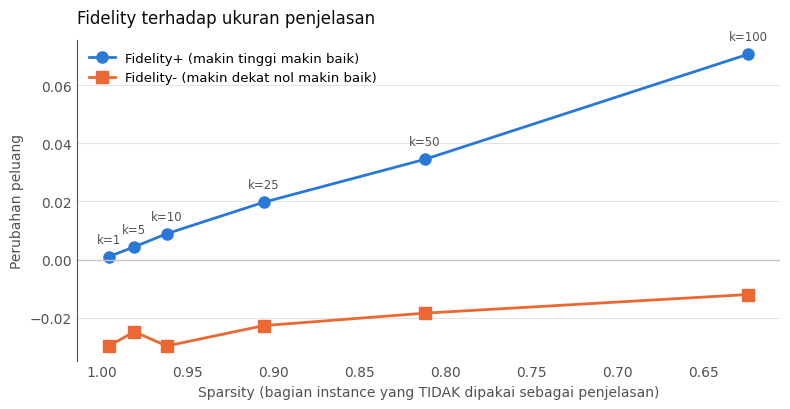

In [67]:
fig, ax = plt.subplots(figsize=(8, 4.2))

ax.plot(kurva_fidelity['Sparsity'], kurva_fidelity['Fidelity+'],
        marker='o', markersize=8, linewidth=2, color=WARNA['author'],
        label='Fidelity+ (makin tinggi makin baik)')
ax.plot(kurva_fidelity['Sparsity'], kurva_fidelity['Fidelity-'],
        marker='s', markersize=8, linewidth=2, color=WARNA['keyword'],
        label='Fidelity- (makin dekat nol makin baik)')

for x, y, k in zip(kurva_fidelity['Sparsity'], kurva_fidelity['Fidelity+'],
                   kurva_fidelity.index):
    ax.annotate(f'k={k}', (x, y), textcoords='offset points', xytext=(0, 10),
                ha='center', fontsize=8.5, color=TINTA_REDUP)

ax.axhline(0, color='#c9c8c2', linewidth=1)
ax.set_xlabel('Sparsity (bagian instance yang TIDAK dipakai sebagai penjelasan)',
              fontsize=10, color=TINTA_REDUP)
ax.set_ylabel('Perubahan peluang', fontsize=10, color=TINTA_REDUP)
ax.set_title('Fidelity terhadap ukuran penjelasan', fontsize=12,
             color=TINTA, loc='left', pad=12)
ax.invert_xaxis()
ax.legend(frameon=False, fontsize=9.5)
rapikan_sumbu(ax, 'y')

plt.tight_layout()
simpan_gambar('Kurva_Fidelity.png')
plt.show()

#### 9.4.1 Ablasi Kelompok per Metapath

Ablasi di 9.2 membuang instance satu per satu. Bila banyak instance saling mirip, membuang satu saja hampir tidak mengubah peluang, walaupun mereka penting. Di sini semua instance dari satu metapath (APA, APKPA, atau APrPrA) dibuang sekaligus pada 200 pasangan yang sama.

Ukurannya rata-rata penurunan peluang, PN, dan rata-rata perubahan peringkat. Perubahan peringkat positif berarti dosen turun. Dosen yang tidak punya instance pada suatu metapath tidak dihitung untuk metapath itu, jadi n bisa kurang dari 200.

1. **Mengapa dibuang sekelompok.**

   Covert dkk. (2021), *JMLR* ([jmlr.org/papers/v22/20-1316](https://jmlr.org/papers/v22/20-1316.html)):

   > *"Measuring a single marginal contribution, either by removing or including individual players, ignores player interactions; for example, removing individual players may lead to near-zero attributions for groups of correlated features, even if they are collectively important."*

   Instance satu metapath milik seorang dosen bisa saling mirip, jadi diuji juga sebagai satu kelompok.

2. **Mengapa kelompoknya per metapath.**

   Yuan dkk. (2022), *IEEE TPAMI* ([10.1109/TPAMI.2022.3204236](https://doi.org/10.1109/TPAMI.2022.3204236)):

   > *"Obviously, SubgraphX outperforms the other methods significantly and consistently, showing that subgraph-level explanations are more desired for GNN models."*

   Semua instance satu metapath membentuk bagian graph yang lebih besar daripada satu jalur, dan metapath adalah satuan yang dipakai MAGNN.

In [68]:
baris_ablasi = []
for d, t, dasar_p, asli_p, pengaruh_p, benar in bahan_pasangan:
    peringkat_awal = peringkat_baru(d, peluang_per_topik[t], dasar_p)
    for nama in METAPATH_DOSEN:
        if asli_p[nama].size(0) == 0:
            continue
        tanpa = dict(asli_p)
        tanpa[nama] = asli_p[nama][:0]
        peluang_tanpa = peluang_rekomendasi(d, t, tanpa)
        peringkat_akhir = peringkat_baru(d, peluang_per_topik[t], peluang_tanpa)
        baris_ablasi.append({'benar': benar, 'Metapath': nama,
                             'Penurunan peluang': dasar_p - peluang_tanpa,
                             'PN': float(peringkat_akhir > 10),
                             'Perubahan peringkat': peringkat_akhir - peringkat_awal})

hasil_ablasi = pd.DataFrame(baris_ablasi)
kelompok_ablasi = {'gabungan': hasil_ablasi,
                   'benar': hasil_ablasi[hasil_ablasi['benar']],
                   'salah': hasil_ablasi[~hasil_ablasi['benar']]}

baris_tabel = []
for kelompok, bagian in kelompok_ablasi.items():
    for nama in METAPATH_DOSEN:
        isi = bagian[bagian['Metapath'] == nama]
        baris_tabel.append({'Kelompok': kelompok, 'Metapath': nama, 'n': len(isi),
                            'Penurunan peluang': tulis_selang(isi['Penurunan peluang']),
                            'PN': tulis_selang(isi['PN'], 3),
                            'Perubahan peringkat': tulis_selang(isi['Perubahan peringkat'], 2)})

tabel_ablasi = pd.DataFrame(baris_tabel).set_index(['Kelompok', 'Metapath'])
tabel_ablasi.index.names = [f'Kelompok ({len(pasangan)} pasangan, seed {SEED})', 'Metapath']
display(tabel_ablasi)

n        Penurunan peluang  \
Kelompok (200 pasangan, seed 42) Metapath                                 
gabungan                         APA       200  0.1195 [0.0909, 0.1488]   
                                 APKPA     200  0.1089 [0.0806, 0.1396]   
                                 APrPrA    200  0.0708 [0.0464, 0.0974]   
benar                            APA       100  0.1098 [0.0712, 0.1527]   
                                 APKPA     100  0.1175 [0.0775, 0.1616]   
                                 APrPrA    100  0.0417 [0.0189, 0.0682]   
salah                            APA       100  0.1292 [0.0906, 0.1700]   
                                 APKPA     100  0.1004 [0.0608, 0.1429]   
                                 APrPrA    100  0.0998 [0.0580, 0.1449]   

                                                             PN  \
Kelompok (200 pasangan, seed 42) Metapath                         
gabungan                         APA       0.265 [0.205, 0.325]   
                                 APKPA     0.160 [0.110, 0.210]   
                                 APrPrA    0.145 [0.095, 0.195]   
benar                            APA       0.240 [0.160, 0.320]   
                                 APKPA     0.190 [0.120, 0.270]   
                                 APrPrA    0.100 [0.050, 0.160]   
salah                            APA       0.290 [0.200, 0.380]   
                                 APKPA     0.130 [0.070, 0.200]   
                                 APrPrA    0.190 [0.120, 0.270]   

                                          Perubahan peringkat  
Kelompok (200 pasangan, seed 42) Metapath                      
gabungan                         APA       8.45 [6.28, 10.77]  
                                 APKPA      7.17 [4.81, 9.78]  
                                 APrPrA     5.56 [3.56, 7.71]  
benar                            APA       8.40 [5.19, 12.02]  
                                 APKPA     9.08 [5.20, 13.30]  
                                 APrPrA     3.73 [1.61, 6.18]  
salah                            APA       8.49 [5.81, 11.34]  
                                 APKPA      5.27 [2.64, 8.37]  
                                 APrPrA    7.39 [4.20, 10.90]

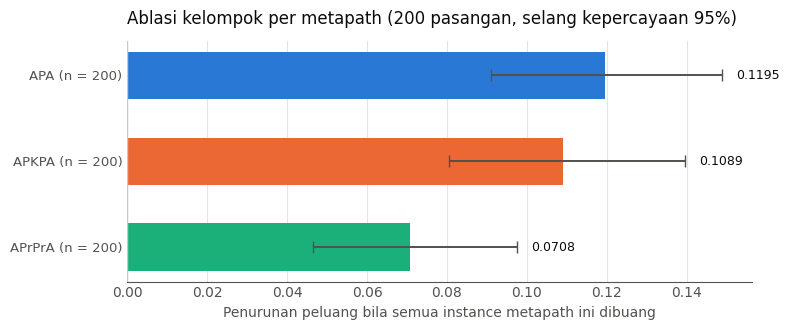

In [69]:
nilai, bawah, atas, label = [], [], [], []
for nama in METAPATH_DOSEN:
    isi = hasil_ablasi[hasil_ablasi['Metapath'] == nama]['Penurunan peluang']
    rata, batas_bawah, batas_atas = selang_bootstrap(isi)
    nilai.append(rata)
    bawah.append(rata - batas_bawah)
    atas.append(batas_atas - rata)
    label.append(f"{nama} (n = {len(isi)})")

fig, ax = plt.subplots(figsize=(8, 3.4))
posisi = np.arange(len(nilai))[::-1]
ax.barh(posisi, nilai, height=0.55, color=[WARNA_METAPATH[n] for n in METAPATH_DOSEN],
        xerr=[bawah, atas], error_kw=dict(ecolor=TINTA_REDUP, capsize=4, lw=1.4))

for y, v, e in zip(posisi, nilai, atas):
    ax.text(max(v + e, 0) + max(nilai) * 0.03, y, f'{v:.4f}', va='center', fontsize=9, color=TINTA)

ax.axvline(0, color='#c9c8c2', linewidth=1)
ax.set_yticks(posisi)
ax.set_yticklabels(label, fontsize=9.5, color=TINTA)
ax.set_xlabel('Penurunan peluang bila semua instance metapath ini dibuang',
              fontsize=10, color=TINTA_REDUP)
ax.set_title(f'Ablasi kelompok per metapath ({len(pasangan)} pasangan, selang kepercayaan 95%)',
             fontsize=12, color=TINTA, loc='left', pad=12)
rapikan_sumbu(ax, 'x')

plt.tight_layout()
simpan_gambar('Ablasi_Metapath.png')
plt.show()

Membuang seluruh instance APrPrA menurunkan peluang rekomendasi rata-rata 0,0081, dan membuang seluruh instance APKPA menurunkan 0,0048, dengan selang kepercayaan yang saling tumpang tindih. Sebaliknya, membuang seluruh instance APA tidak menurunkan peluang. Bila diukur dari perubahan peringkat, APKPA lebih berpengaruh: 29% rekomendasi keluar dari 10 besar, dibanding 12% pada APrPrA. Dengan demikian, bukti yang paling menentukan rekomendasi adalah kesamaan topik antardosen, diikuti hubungan antarprodi, sedangkan hubungan rekan penulis langsung tidak berperan.

### 9.5 Penjelasan dalam Bahasa Pengguna

In [70]:
def sebut_dosen(idx):
    return nama_dosen_idx[idx].split(',')[0]


def sebut_paper(idx, batas=70):
    judul = str(judul_paper_idx[idx])
    return judul if len(judul) <= batas else judul[:batas] + '...'


def narasikan(nama_metapath, jalur):
    j = [int(x) for x in jalur.tolist()]

    if nama_metapath == 'APA':
        if j[0] == j[2]:
            return f"menulis sendiri paper \"{sebut_paper(j[1])}\""
        return (f"menulis paper \"{sebut_paper(j[1])}\" "
                f"bersama {sebut_dosen(j[2])}")

    if nama_metapath == 'APKPA':
        bagian = (f"menulis paper \"{sebut_paper(j[1])}\" "
                  f"yang membahas topik '{semua_topik[j[2]]}'")
        if j[0] == j[4]:
            return bagian
        return (bagian + f"; topik yang sama juga dibahas paper "
                         f"\"{sebut_paper(j[3])}\" karya {sebut_dosen(j[4])}")

    if nama_metapath == 'APrPrA':
        if j[1] == j[2]:
            return (f"berada di {prodi_dari_idx[j[1]]}, satu prodi dengan "
                    f"{sebut_dosen(j[3])}")
        return (f"berada di {prodi_dari_idx[j[1]]}, yang pernah berkolaborasi lintas prodi "
                f"dengan {prodi_dari_idx[j[2]]} tempat {sebut_dosen(j[3])} berada")

    return ' -> '.join(str(x) for x in j)


print(f"Mengapa {nama_dosen_idx[idx_dosen_contoh]}")
print(f"direkomendasikan untuk topik '{topik_contoh}'?")
print(f"Peluang relevansi menurut model: {dasar:.1%}\n")
print("Bukti terkuat, diurutkan dari yang paling menentukan:\n")

for nomor, p in enumerate(pengaruh[:5], start=1):
    jalur = asli[p['metapath']][p['baris']]
    print(f"{nomor}. [{p['metapath']:<6}] {sebut_dosen(idx_dosen_contoh)} "
          f"{narasikan(p['metapath'], jalur)}")
    print(f"   (tanpa jalur ini, peluang turun {p['penurunan']:.5f})\n")

Mengapa Anita Qoiriah, S.Kom., M.Kom.
direkomendasikan untuk topik 'computer science'?
Peluang relevansi menurut model: 97.8%

Bukti terkuat, diurutkan dari yang paling menentukan:

1. [APKPA ] Anita Qoiriah menulis paper "Sistem Rekomendasi Wedding Organizer Menggunakan Metode Content-Based ..." yang membahas topik 'computer science'; topik yang sama juga dibahas paper "Penerapan Teknologi Multimedia Dalam Meningkatkan Minat Beribadah Rema..." karya Aditya Prapanca
   (tanpa jalur ini, peluang turun 0.00011)

2. [APKPA ] Anita Qoiriah menulis paper "Sistem Rekomendasi Wedding Organizer Menggunakan Metode Content-Based ..." yang membahas topik 'computer science'; topik yang sama juga dibahas paper "Penerapan Teknologi Semantic Web Dengan Studi Kasus Struktur Air (H2O)" karya Aditya Prapanca
   (tanpa jalur ini, peluang turun 0.00011)

3. [APKPA ] Anita Qoiriah menulis paper "Penerapan Algoritma Fp-Growth Dan K-Means Pada Data Transaksi Minimark..." yang membahas topik 'art'; topik yang

### 9.6 Grafik Kepentingan Bukti

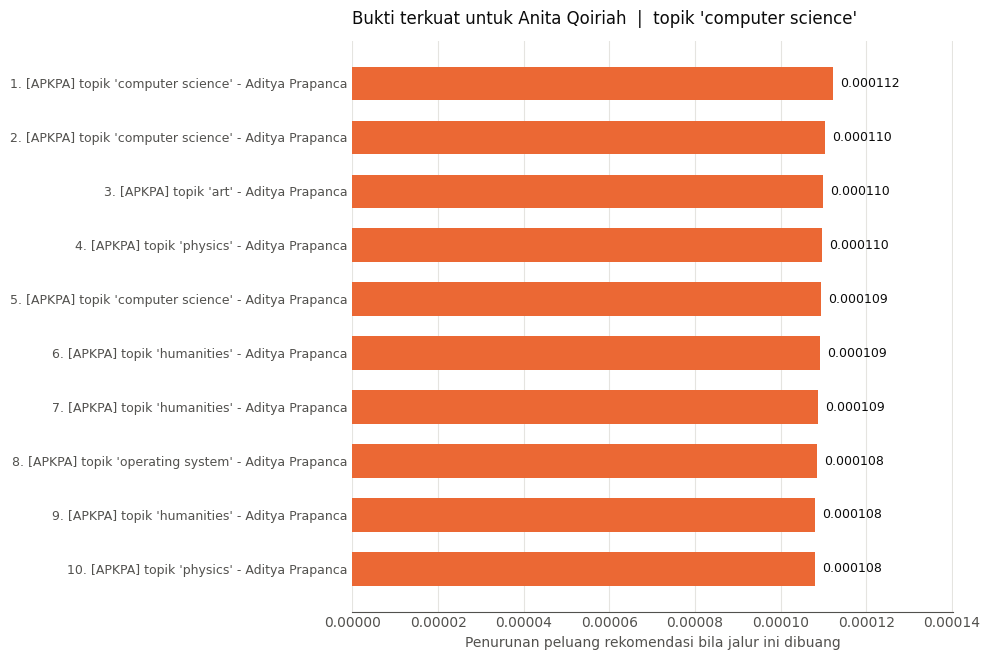

Jalur lengkap:
  1. Anita Qoiriah menulis paper "Sistem Rekomendasi Wedding Organizer Menggunakan Metode Content-Based ..." yang membahas topik 'computer science'; topik yang sama juga dibahas paper "Penerapan Teknologi Multimedia Dalam Meningkatkan Minat Beribadah Rema..." karya Aditya Prapanca
  2. Anita Qoiriah menulis paper "Sistem Rekomendasi Wedding Organizer Menggunakan Metode Content-Based ..." yang membahas topik 'computer science'; topik yang sama juga dibahas paper "Penerapan Teknologi Semantic Web Dengan Studi Kasus Struktur Air (H2O)" karya Aditya Prapanca
  3. Anita Qoiriah menulis paper "Penerapan Algoritma Fp-Growth Dan K-Means Pada Data Transaksi Minimark..." yang membahas topik 'art'; topik yang sama juga dibahas paper "Pengembangan Aplikasi Terpadu Untuk Meningkatkan Layanan Dan Akses Mah..." karya Aditya Prapanca
  4. Anita Qoiriah menulis paper "Analisis Tingkat Kesiapan Dan Kematangan Implementasi Iso 27001: 2013 ..." yang membahas topik 'physics'; topik yang sama

In [71]:
def label_ringkas(nama_metapath, jalur):
    j = [int(x) for x in jalur.tolist()]

    if nama_metapath == 'APA':
        return 'menulis sendiri' if j[0] == j[2] else f'bersama {sebut_dosen(j[2])}'

    if nama_metapath == 'APKPA':
        awal = f"topik '{semua_topik[j[2]]}'"
        return awal if j[0] == j[4] else f"{awal} - {sebut_dosen(j[4])}"

    if nama_metapath == 'APrPrA':
        return f"{prodi_dari_idx[j[2]]} - {sebut_dosen(j[3])}"

    return str(j)

def gambar_kepentingan(pengaruh, asli, idx_dosen, topik, top_n=10, simpan=None):
    pilihan = pengaruh[:top_n]

    label, nilai, warna = [], [], []
    for nomor, p in enumerate(pilihan, start=1):
        ringkas = label_ringkas(p['metapath'], asli[p['metapath']][p['baris']])
        if len(ringkas) > 46:
            ringkas = ringkas[:46] + '...'
        label.append(f"{nomor}. [{p['metapath']}] {ringkas}")
        nilai.append(p['penurunan'])
        warna.append(WARNA_METAPATH[p['metapath']])

    fig, ax = plt.subplots(figsize=(10, 0.5 * len(pilihan) + 1.7))
    posisi = np.arange(len(pilihan))[::-1]
    ax.barh(posisi, nilai, height=0.62, color=warna)

    batas = max(nilai) if max(nilai) > 0 else 1
    for y, v in zip(posisi, nilai):
        ax.text(v + batas * 0.015, y, f'{v:.6f}', va='center', fontsize=9, color=TINTA)

    ax.set_yticks(posisi)
    ax.set_yticklabels(label, fontsize=9, color=TINTA)
    ax.set_xlim(0, batas * 1.25)
    ax.set_xlabel('Penurunan peluang rekomendasi bila jalur ini dibuang',
                  fontsize=10, color=TINTA_REDUP)
    ax.set_title(f"Bukti terkuat untuk {sebut_dosen(idx_dosen)}  |  topik '{topik}'",
                 fontsize=12, color=TINTA, pad=12, loc='left')
    rapikan_sumbu(ax, 'x')

    muncul = list(dict.fromkeys(p['metapath'] for p in pilihan))
    if len(muncul) > 1:
        ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=WARNA_METAPATH[m], label=m)
                           for m in muncul],
                  loc='lower right', frameon=False, fontsize=9)

    plt.tight_layout()
    if simpan:
        simpan_gambar(simpan)
    plt.show()

    print("Jalur lengkap:")
    for nomor, p in enumerate(pilihan, start=1):
        jalur = asli[p['metapath']][p['baris']]
        print(f"  {nomor}. {sebut_dosen(idx_dosen)} {narasikan(p['metapath'], jalur)}")

gambar_kepentingan(pengaruh, asli, idx_dosen_contoh, topik_contoh,
                   simpan='Penjelasan_Kepentingan.png')

### 9.7 Diagram Subgraph Penjelasan

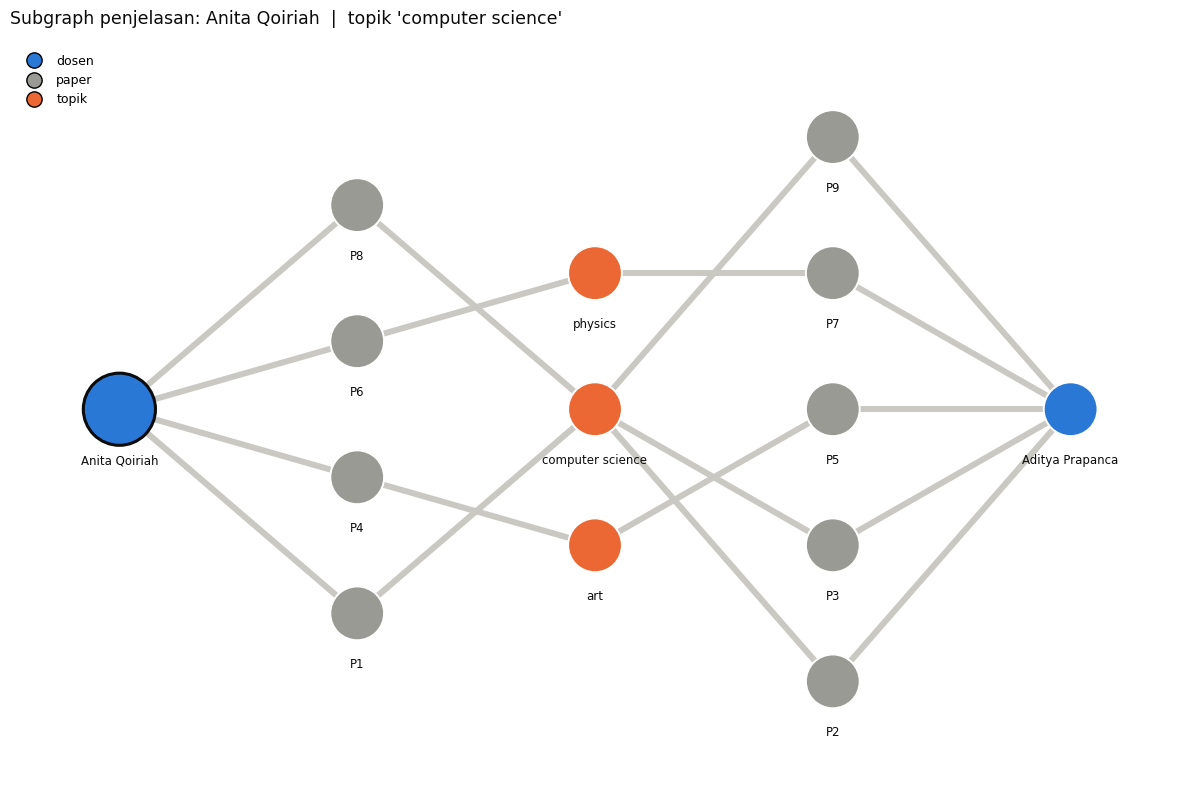

Keterangan kode paper:
  P1 = Sistem Rekomendasi Wedding Organizer Menggunakan Metode Content-Based Filtering Dengan A...
  P2 = Penerapan Teknologi Multimedia Dalam Meningkatkan Minat Beribadah Remaja Dan Pemuda
  P3 = Penerapan Teknologi Semantic Web Dengan Studi Kasus Struktur Air (H2O)
  P4 = Penerapan Algoritma Fp-Growth Dan K-Means Pada Data Transaksi Minimarket
  P5 = Pengembangan Aplikasi Terpadu Untuk Meningkatkan Layanan Dan Akses Mahasiswa Terhadap Ru...
  P6 = Analisis Tingkat Kesiapan Dan Kematangan Implementasi Iso 27001: 2013 Menggunakan Indeks...
  P7 = Modifikasi Cipher Kriptografi Caesar Yang Dapat Dibaca Dengan Menggunakan Kamus Bahasa I...
  P8 = Implementasi Algoritma Fisher-Yates Shuffle Dan Fuzzy Tsukamoto Pada Game Petualangan Si...
  P9 = Manajemen User Mikrotik Berbasis Telegram Bot


In [72]:
def gambar_subgraph(pengaruh, asli, idx_dosen, topik, top_k=5, simpan=None):
    G = nx.Graph()
    tebal = {}

    for p in pengaruh[:top_k]:
        tipe = TIPE_JALUR[p['metapath']]
        jalur = [int(x) for x in asli[p['metapath']][p['baris']].tolist()]
        simpul = list(zip(tipe, jalur))

        for a, b in zip(simpul, simpul[1:]):
            if a == b:
                continue
            G.add_edge(a, b)
            tebal[(a, b)] = max(tebal.get((a, b), 0), p['penurunan'])

    sumber = ('author', idx_dosen)
    if sumber not in G:
        print("Tidak ada jalur yang bisa digambar.")
        return

    kode_paper = {}
    for tipe, idx in G.nodes():
        if tipe == 'paper':
            kode_paper.setdefault(idx, f'P{len(kode_paper) + 1}')

    def label(node):
        tipe, idx = node
        if tipe == 'author':
            return sebut_dosen(idx)
        if tipe == 'paper':
            return kode_paper[idx]
        if tipe == 'keyword':
            return semua_topik[idx]
        return prodi_dari_idx[idx].replace('S1 ', '').replace('S2 ', '').replace('S3 ', '')

    langkah = nx.single_source_shortest_path_length(G, sumber)
    per_lapis = defaultdict(list)
    for node, jarak in langkah.items():
        per_lapis[jarak].append(node)

    posisi = {}
    for jarak, daftar in per_lapis.items():
        for urutan, node in enumerate(sorted(daftar, key=label)):
            posisi[node] = (jarak * 1.9, urutan - (len(daftar) - 1) / 2)

    fig, ax = plt.subplots(figsize=(12, max(4.2, 1.15 * max(
        len(v) for v in per_lapis.values()) + 2.2)))

    maks = max(tebal.values()) if tebal else 1
    for (a, b), berat in tebal.items():
        if a in posisi and b in posisi:
            nx.draw_networkx_edges(G, posisi, edgelist=[(a, b)], ax=ax,
                                   width=1.4 + 3.0 * (berat / maks),
                                   edge_color='#c9c8c2')

    for tipe in ['paper', 'prodi', 'keyword', 'author']:
        anggota = [n for n in G.nodes() if n[0] == tipe]
        if not anggota:
            continue
        nx.draw_networkx_nodes(
            G, posisi, nodelist=anggota, ax=ax,
            node_color=WARNA[tipe],
            node_size=[2700 if n == sumber else 1500 for n in anggota],
            edgecolors=[TINTA if n == sumber else 'white' for n in anggota],
            linewidths=[2.2 if n == sumber else 1.4 for n in anggota])

    for node, (x, y) in posisi.items():
        teks = label(node)
        if len(teks) > 32:
            teks = teks[:32] + '...'
        ax.text(x, y - 0.33, teks, ha='center', va='top',
                fontsize=8.5, color=TINTA)

    ax.set_title(f"Subgraph penjelasan: {sebut_dosen(idx_dosen)}  |  topik '{topik}'",
                 fontsize=12.5, color=TINTA, pad=14, loc='left')
    nama_tipe = {'author': 'dosen', 'paper': 'paper',
                 'keyword': 'topik', 'prodi': 'prodi'}
    ada_tipe = [t for t in nama_tipe if any(n[0] == t for n in G.nodes())]

    ax.legend(handles=[plt.Line2D([0], [0], marker='o', color='none',
                                  label=nama_tipe[t], markerfacecolor=WARNA[t],
                                  markersize=11)
                       for t in ada_tipe],
              loc='upper left', frameon=False, fontsize=9)
    ax.margins(x=0.10, y=0.14)
    ax.axis('off')
    plt.tight_layout()
    if simpan:
        simpan_gambar(simpan)
    plt.show()

    if kode_paper:
        print("Keterangan kode paper:")
        for idx, kode in kode_paper.items():
            print(f"  {kode} = {sebut_paper(idx, 88)}")


gambar_subgraph(pengaruh, asli, idx_dosen_contoh, topik_contoh,
                simpan='Penjelasan_Subgraph.png')

### 9.8 Penjelasan Tingkat Model

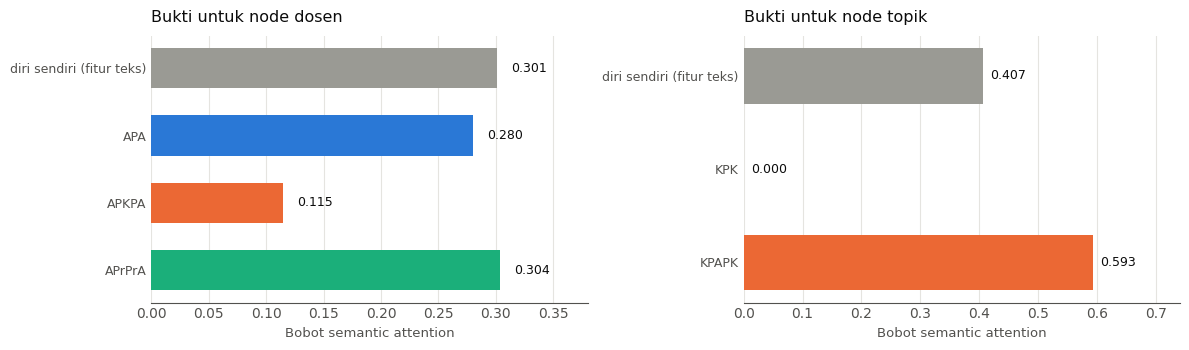

Bukti paling dipercaya untuk node dosen: APrPrA (bobot 0.3038)


In [73]:
with torch.no_grad():
    magnn.encode(graph_latih)

fig, sumbu = plt.subplots(1, 2, figsize=(12, 3.6))

for ax, (nama_target, daftar, judul) in zip(sumbu, [
        ('author', METAPATH_DOSEN, 'Bukti untuk node dosen'),
        ('keyword', METAPATH_TOPIK, 'Bukti untuk node topik')]):

    label = ['diri sendiri (fitur teks)'] + daftar
    nilai = magnn.bobot_semantik[nama_target].tolist()
    warna = [WARNA_METAPATH[l] for l in label]

    posisi = np.arange(len(label))[::-1]
    ax.barh(posisi, nilai, height=0.6, color=warna)

    for y, v in zip(posisi, nilai):
        ax.text(v + 0.012, y, f'{v:.3f}', va='center', fontsize=9, color=TINTA)

    ax.set_yticks(posisi)
    ax.set_yticklabels(label, fontsize=9, color=TINTA)
    ax.set_xlim(0, max(nilai) * 1.25)
    ax.set_xlabel('Bobot semantic attention', fontsize=9.5, color=TINTA_REDUP)
    ax.set_title(judul, fontsize=11.5, color=TINTA, loc='left', pad=10)
    rapikan_sumbu(ax, 'x')

plt.tight_layout()
simpan_gambar('Bobot_Metapath.png')
plt.show()

teratas = max(zip(magnn.bobot_semantik['author'].tolist(),
                  ['diri sendiri'] + METAPATH_DOSEN))
print(f"Bukti paling dipercaya untuk node dosen: {teratas[1]} (bobot {teratas[0]:.4f})")

## **10. Visualisasi**

### 10.1 Diagram Skema Knowledge Graph

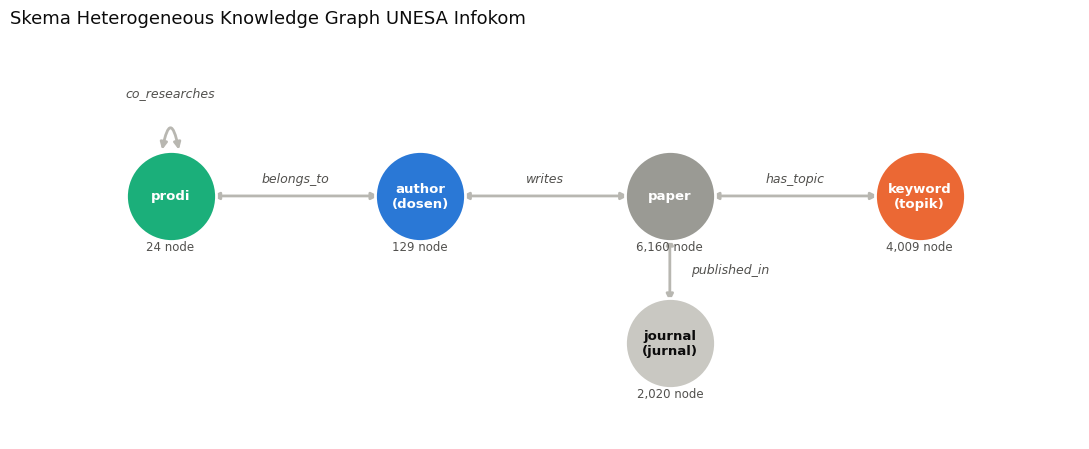

Total node: 12,342
Total edge (graph penuh): 91,046


In [74]:
# Posisi dibuat tetap agar gambarnya selalu sama setiap dijalankan.
JURNAL_WARNA = '#c9c8c2'

posisi_skema = {
    'prodi': (-2.1, 0.0),
    'author': (-0.7, 0.0),
    'paper': (0.7, 0.0),
    'keyword': (2.1, 0.0),
    'journal': (0.7, -1.15),
}

jumlah_node_skema = {
    'author': graph_penuh['author'].num_nodes,
    'paper': graph_penuh['paper'].num_nodes,
    'keyword': graph_penuh['keyword'].num_nodes,
    'journal': graph_penuh['journal'].num_nodes,
    'prodi': graph_penuh['prodi'].num_nodes,
}

nama_tampil = {'author': 'author\n(dosen)', 'paper': 'paper', 'keyword': 'keyword\n(topik)',
               'journal': 'journal\n(jurnal)', 'prodi': 'prodi'}

relasi_skema = [
    ('author', 'paper', 'writes'),
    ('paper', 'keyword', 'has_topic'),
    ('paper', 'journal', 'published_in'),
    ('author', 'prodi', 'belongs_to'),
]

fig, ax = plt.subplots(figsize=(11, 4.6))

for awal, akhir, nama in relasi_skema:
    x1, y1 = posisi_skema[awal]
    x2, y2 = posisi_skema[akhir]
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='<|-|>', color='#b8b7b1',
                                linewidth=2, shrinkA=30, shrinkB=30))
    if abs(y2 - y1) > abs(x2 - x1):
        ax.text(x1 + 0.12, (y1 + y2) / 2, nama, ha='left', va='center',
                fontsize=9, color=TINTA_REDUP, style='italic')
    else:
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.11, nama, ha='center',
                fontsize=9, color=TINTA_REDUP, style='italic')

xp, yp = posisi_skema['prodi']
ax.annotate('', xy=(xp - 0.05, yp + 0.34), xytext=(xp + 0.05, yp + 0.34),
            arrowprops=dict(arrowstyle='<|-|>', color='#b8b7b1', linewidth=2,
                            connectionstyle='arc3,rad=2.6'))
ax.text(xp, yp + 0.78, 'co_researches', ha='center', fontsize=9,
        color=TINTA_REDUP, style='italic')

for tipe, (x, y) in posisi_skema.items():
    warna = JURNAL_WARNA if tipe == 'journal' else WARNA[tipe]
    ax.scatter([x], [y], s=4200, c=warna, edgecolors='white', linewidths=2, zorder=3)
    ax.text(x, y, nama_tampil[tipe], ha='center', va='center', fontsize=9.5,
            color='white' if tipe != 'journal' else TINTA, zorder=4, fontweight='bold')
    ax.text(x, y - 0.42, f"{jumlah_node_skema[tipe]:,} node", ha='center',
            fontsize=8.5, color=TINTA_REDUP)

ax.set_title('Skema Heterogeneous Knowledge Graph UNESA Infokom',
             fontsize=13, color=TINTA, loc='left', pad=14)
ax.set_xlim(-3.0, 3.0)
ax.set_ylim(-1.9, 1.2)
ax.axis('off')
plt.tight_layout()
simpan_gambar('Skema_Knowledge_Graph.png')
plt.show()

print(f"Total node: {sum(jumlah_node_skema.values()):,}")
print(f"Total edge (graph penuh): "
      f"{sum(graph_penuh[r].edge_index.size(1) for r in graph_penuh.edge_types):,}")

Knowledge Graph yang dibangun terdiri atas lima jenis node, yaitu prodi (24), dosen (129), paper (6.160), topik (4.009), dan jurnal (2.020). Paper menjadi pusat graph karena menghubungkan dosen dengan topik dan jurnal, sehingga keahlian dosen terhadap suatu topik dibaca melalui jalur dosen, paper, lalu topik. Node prodi menambahkan dimensi institusional: setiap dosen terhubung ke prodinya melalui relasi belongs_to, dan dua prodi terhubung melalui relasi co_researches apabila dosen dari kedua prodi tersebut pernah menulis paper bersama.

### 10.2 Perbandingan Seluruh Metode

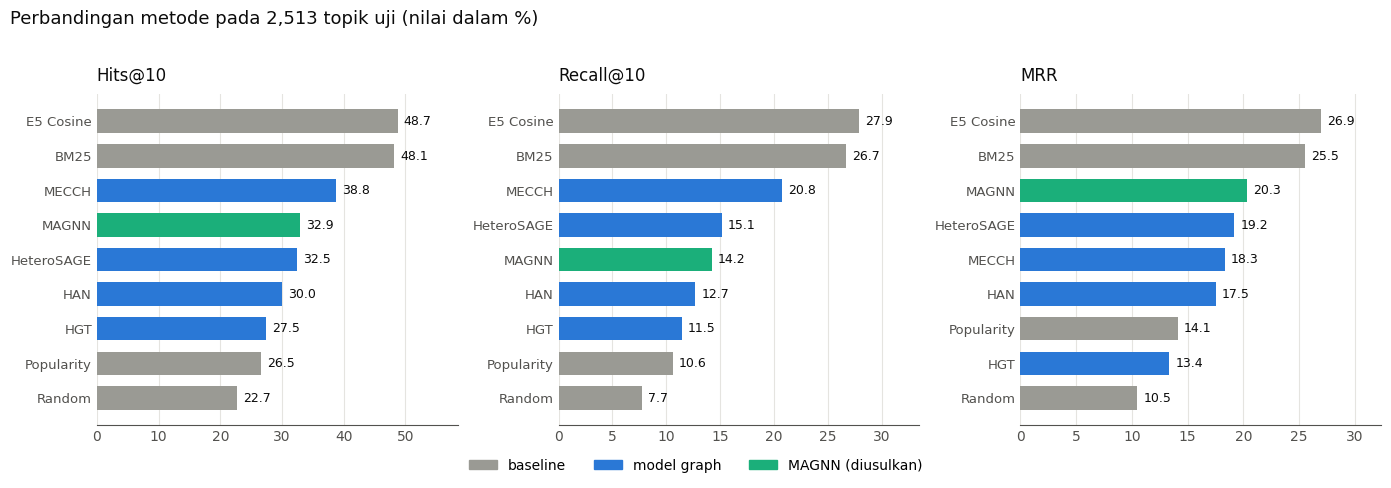

In [75]:
KELUARGA = {
    'Random': 'baseline', 'Popularity': 'baseline',
    'BM25': 'baseline', 'E5 Cosine': 'baseline',
    'HAN': 'gnn', 'HGT': 'gnn', 'HeteroSAGE': 'gnn', 'MECCH': 'gnn', 'MAGNN': 'magnn',
}
WARNA_KELUARGA = {'baseline': '#9a9a94', 'gnn': WARNA['author'], 'magnn': WARNA['prodi']}

metrik_tampil = ['Hits@10', 'Recall@10', 'MRR']
fig, sumbu = plt.subplots(1, len(metrik_tampil), figsize=(14, 4.4))

for ax, metrik in zip(sumbu, metrik_tampil):
    urut = tabel_akhir[metrik].sort_values()
    warna = [WARNA_KELUARGA[KELUARGA[m]] for m in urut.index]

    posisi = np.arange(len(urut))
    ax.barh(posisi, urut.values, height=0.68, color=warna)

    for y, v in zip(posisi, urut.values):
        ax.text(v + urut.max() * 0.02, y, f'{v:.1f}', va='center',
                fontsize=9, color=TINTA)

    ax.set_yticks(posisi)
    ax.set_yticklabels(urut.index, fontsize=9.5, color=TINTA)
    ax.set_xlim(0, urut.max() * 1.20)
    ax.set_title(metrik, fontsize=12, color=TINTA, loc='left', pad=10)
    rapikan_sumbu(ax, 'x')

fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=WARNA_KELUARGA[k], label=n)
                    for k, n in [('baseline', 'baseline'), ('gnn', 'model graph'),
                                 ('magnn', 'MAGNN (diusulkan)')]],
           loc='lower center', ncol=3, frameon=False, fontsize=10,
           bbox_to_anchor=(0.5, -0.06))

fig.suptitle(f'Perbandingan metode pada {len(topik_diuji):,} topik uji (nilai dalam %)',
             fontsize=13, color=TINTA, x=0.01, ha='left', y=1.02)
plt.tight_layout()
simpan_gambar('Perbandingan_Metode.png')
plt.show()

### 10.3 Topik Dikenal vs Cold-start

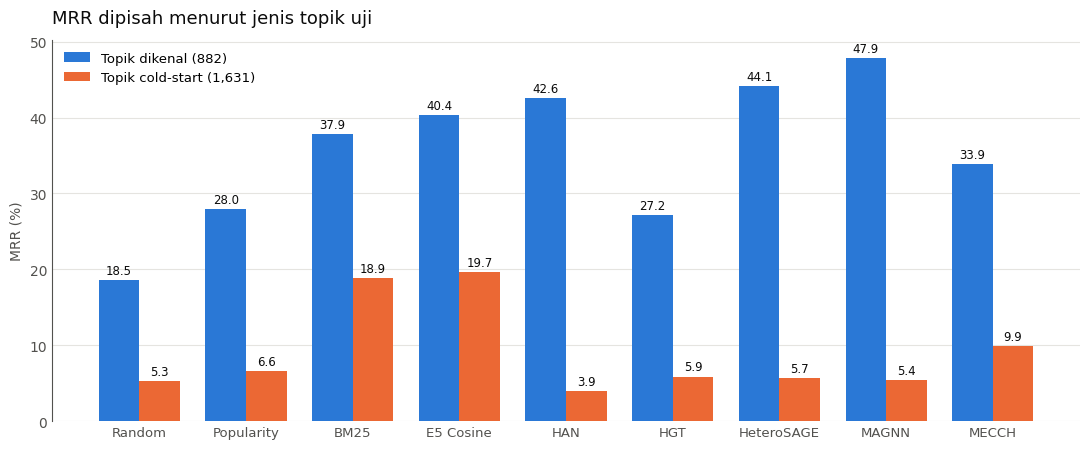

In [76]:
metrik_pisah = 'MRR'
data_pisah = tabel_pisah_model[metrik_pisah].unstack()
data_pisah = data_pisah.loc[[m for m in tabel_akhir.index if m in data_pisah.index]]

fig, ax = plt.subplots(figsize=(11, 4.6))

x = np.arange(len(data_pisah))
lebar = 0.38

ax.bar(x - lebar / 2, data_pisah['Dikenal'], lebar,
       label=f"Topik dikenal ({len(topik_dikenal_uji):,})", color=WARNA['author'])
ax.bar(x + lebar / 2, data_pisah['Cold-start'], lebar,
       label=f"Topik cold-start ({len(topik_baru_uji):,})", color=WARNA['keyword'])

for posisi, nilai in zip(x - lebar / 2, data_pisah['Dikenal']):
    ax.text(posisi, nilai + 0.8, f'{nilai:.1f}', ha='center', fontsize=8.5, color=TINTA)
for posisi, nilai in zip(x + lebar / 2, data_pisah['Cold-start']):
    ax.text(posisi, nilai + 0.8, f'{nilai:.1f}', ha='center', fontsize=8.5, color=TINTA)

ax.set_xticks(x)
ax.set_xticklabels(data_pisah.index, fontsize=9.5, color=TINTA)
ax.set_ylabel(f'{metrik_pisah} (%)', fontsize=10, color=TINTA_REDUP)
ax.set_title(f'{metrik_pisah} dipisah menurut jenis topik uji',
             fontsize=13, color=TINTA, loc='left', pad=12)
ax.legend(frameon=False, fontsize=9.5)
rapikan_sumbu(ax, 'y')

plt.tight_layout()
simpan_gambar('Dikenal_vs_Coldstart.png')
plt.show()

## **11. Pengujian Ulang dengan Beberapa Seed**

### 11.1 Menjalankan Ulang

In [78]:
DAFTAR_SEED = [42, 7, 2024]
DAFTAR_MODEL = ['HAN', 'HGT', 'HeteroSAGE', 'MAGNN', 'MECCH']

instance_awal = instance_metapath
catatan_seed = []

for nomor_seed, seed in enumerate(DAFTAR_SEED, start=1):
    print(f"\n=== Seed {seed}  ({nomor_seed}/{len(DAFTAR_SEED)}) ===")

    instance_metapath = siapkan_instance(graph_latih, contoh_dosen=150,
                                         contoh_topik=30, seed=seed)

    for jenis in DAFTAR_MODEL:
        model, _ = latih_model(jenis, graph_latih, seed=seed, tampilkan_tiap=0)
        skor = evaluasi_model(model, graph_latih)

        catatan = skor.to_dict()
        catatan['Model'] = jenis
        catatan['Seed'] = seed
        catatan_seed.append(catatan)

        print(f"  {jenis:<11} Hits@10 {skor['Hits@10']:5.2f} | "
              f"Recall@10 {skor['Recall@10']:5.2f} | MRR {skor['MRR']:5.2f}")

instance_metapath = instance_awal

hasil_seed = pd.DataFrame(catatan_seed)
print(f"\nSelesai: {len(hasil_seed)} kombinasi model x seed")


=== Seed 42  (1/3) ===
  HAN         Hits@10 30.00 | Recall@10 12.70 | MRR 17.50
  HGT         Hits@10 27.46 | Recall@10 11.46 | MRR 13.36
  HeteroSAGE  Hits@10 32.47 | Recall@10 15.13 | MRR 19.19
  MAGNN       Hits@10 32.87 | Recall@10 14.22 | MRR 20.33
  MECCH       Hits@10 38.80 | Recall@10 20.77 | MRR 18.33

=== Seed 7  (2/3) ===
  HAN         Hits@10 30.32 | Recall@10 13.44 | MRR 19.93
  HGT         Hits@10 27.46 | Recall@10 11.46 | MRR 13.21
  HeteroSAGE  Hits@10 33.78 | Recall@10 14.86 | MRR 19.52
  MAGNN       Hits@10 35.89 | Recall@10 17.71 | MRR 21.79
  MECCH       Hits@10 40.83 | Recall@10 22.45 | MRR 20.91

=== Seed 2024  (3/3) ===
  HAN         Hits@10 29.88 | Recall@10 12.63 | MRR 18.52
  HGT         Hits@10 27.46 | Recall@10 11.46 | MRR 13.36
  HeteroSAGE  Hits@10 29.61 | Recall@10 13.85 | MRR 18.30
  MAGNN       Hits@10 31.95 | Recall@10 14.41 | MRR 20.22
  MECCH       Hits@10 40.51 | Recall@10 22.50 | MRR 20.06

Selesai: 15 kombinasi model x seed


### 11.2 Rata-rata dan Simpangan Baku

In [79]:
METRIK = ['Hits@5', 'Hits@10', 'Recall@10', 'MRR']

rata = hasil_seed.groupby('Model')[METRIK].mean()
simpangan = hasil_seed.groupby('Model')[METRIK].std()

ringkas_seed = pd.DataFrame(
    {m: [f"{rata.loc[model, m]:.2f} ± {simpangan.loc[model, m]:.2f}"
         for model in rata.index]
     for m in METRIK},
    index=rata.index,
)
ringkas_seed = ringkas_seed.loc[[m for m in DAFTAR_MODEL if m in ringkas_seed.index]]
ringkas_seed.index.name = f'Model ({len(DAFTAR_SEED)} seed: {", ".join(map(str, DAFTAR_SEED))})'
display(ringkas_seed)

# Baseline tanpa simpangan karena deterministik.
baseline_saja = tabel_akhir.loc[[m for m in ['Random', 'Popularity', 'BM25', 'E5 Cosine']
                                 if m in tabel_akhir.index], METRIK]
baseline_saja.index.name = 'Baseline (deterministik)'
display(baseline_saja.round(2))

,Hits@5,Hits@10,Recall@10,MRR
"Model (3 seed: 42, 7, 2024)",,,,
HAN,24.07 ± 1.84,30.07 ± 0.23,12.93 ± 0.45,18.65 ± 1.22
HGT,16.34 ± 0.74,27.46 ± 0.00,11.46 ± 0.00,13.31 ± 0.09
HeteroSAGE,25.35 ± 1.59,31.95 ± 2.14,14.61 ± 0.68,19.00 ± 0.63
MAGNN,26.45 ± 1.65,33.57 ± 2.06,15.45 ± 1.96,20.78 ± 0.88
MECCH,29.47 ± 4.10,40.05 ± 1.09,21.90 ± 0.98,19.77 ± 1.32


,Hits@5,Hits@10,Recall@10,MRR
Baseline (deterministik),,,,
Random,14.56,22.72,7.71,10.49
Popularity,17.35,26.54,10.62,14.10
BM25,35.85,48.15,26.67,25.54
E5 Cosine,37.56,48.71,27.91,26.94


### 11.3 Selisihnya

In [80]:
metrik_utama = 'MRR'
urut_rata = rata[metrik_utama].sort_values(ascending=False)

print(f"Peringkat menurut {metrik_utama} (rata-rata dari {len(DAFTAR_SEED)} seed)\n")
sebelumnya = None
for model, nilai in urut_rata.items():
    galat = simpangan.loc[model, metrik_utama]
    baris = f"  {model:<11} {nilai:6.2f} ± {galat:.2f}"

    if sebelumnya is not None:
        selisih = sebelumnya[1] - nilai
        gabungan = (galat + simpangan.loc[sebelumnya[0], metrik_utama])
        status = 'jelas lebih rendah' if selisih > gabungan else 'belum bisa dibedakan'
        baris += f"   (selisih {selisih:.2f} dari {sebelumnya[0]}: {status})"

    print(baris)
    sebelumnya = (model, nilai)

Peringkat menurut MRR (rata-rata dari 3 seed)

  MAGNN        20.78 ± 0.88
  MECCH        19.77 ± 1.32   (selisih 1.01 dari MAGNN: belum bisa dibedakan)
  HeteroSAGE   19.00 ± 0.63   (selisih 0.76 dari MECCH: belum bisa dibedakan)
  HAN          18.65 ± 1.22   (selisih 0.35 dari HeteroSAGE: belum bisa dibedakan)
  HGT          13.31 ± 0.09   (selisih 5.34 dari HAN: jelas lebih rendah)


### 11.4 Grafik dengan Rentang Ketidakpastian

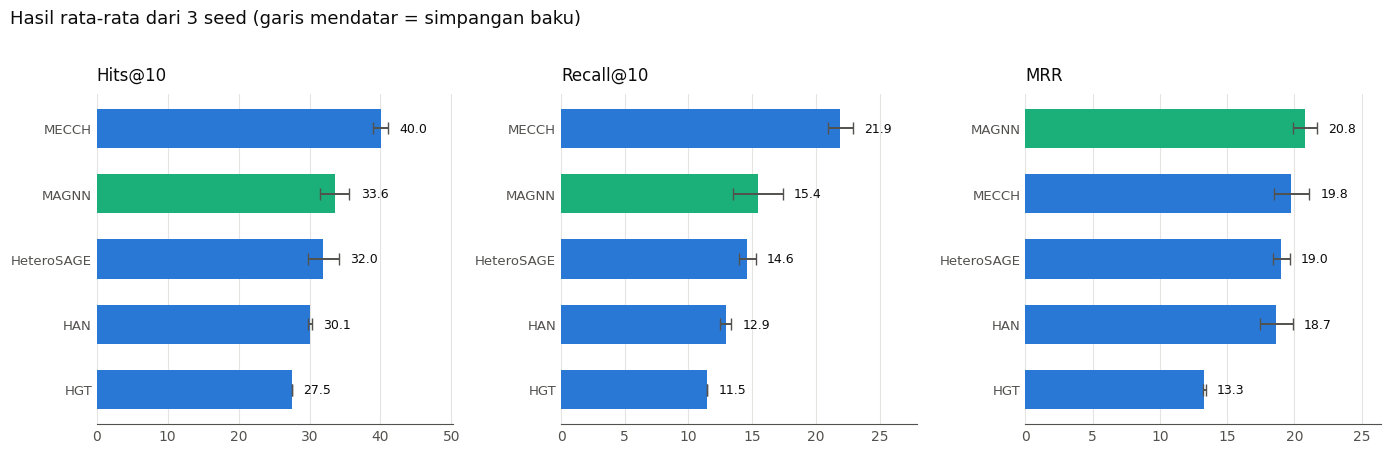

In [81]:
fig, sumbu = plt.subplots(1, 3, figsize=(14, 4.4))

for ax, metrik in zip(sumbu, ['Hits@10', 'Recall@10', 'MRR']):
    urut = rata[metrik].sort_values()
    galat = simpangan.loc[urut.index, metrik]
    warna = [WARNA_KELUARGA[KELUARGA[m]] for m in urut.index]

    posisi = np.arange(len(urut))
    ax.barh(posisi, urut.values, height=0.6, color=warna,
            xerr=galat.values, error_kw=dict(ecolor=TINTA_REDUP, capsize=4, lw=1.4))

    for y, v, e in zip(posisi, urut.values, galat.values):
        ax.text(v + e + urut.max() * 0.04, y, f'{v:.1f}', va='center',
                fontsize=9, color=TINTA)

    ax.set_yticks(posisi)
    ax.set_yticklabels(urut.index, fontsize=9.5, color=TINTA)
    ax.set_xlim(0, (urut.values + galat.values).max() * 1.22)
    ax.set_title(metrik, fontsize=12, color=TINTA, loc='left', pad=10)
    rapikan_sumbu(ax, 'x')

fig.suptitle(f'Hasil rata-rata dari {len(DAFTAR_SEED)} seed '
             f'(garis mendatar = simpangan baku)',
             fontsize=13, color=TINTA, x=0.01, ha='left', y=1.02)
plt.tight_layout()
simpan_gambar('Hasil_MultiSeed.png')
plt.show()